# 15 - Decision Tree regressor (candidate model, Section 4.3.8)

## 1. Objective

This notebook trains and evaluates the **decision tree regressor** candidate of Section 4.3.8
and is the reference source for the Decision Tree rows of Sections 4.3.8 and 4.3.10 of the
documentation. It is a candidate evaluation, not a deployment; the verdict is stated in
Section 10.

The evaluation is standardized with the other supervised candidates: the data, the split, the
metric, the baselines and the search grid are the ones Section 4.3.8 fixes and
`17_random_forest.ipynb` uses, so the tree and the Random Forest are compared on
identical terms.

- **Data**: notebook 13's **as-of** training matrix, in which a row exists only if a forecaster
  could have been asked for it at the start of its month (Section 4.3.6). Section 2.1 audits
  that property on the file itself before any model is fitted.
- **Target**: `volume_demanda_proxy = SUM(QT_ITEM_EVENTO_INFORMADO)` per
  `ID_PLANO x treatment_line_primary x UF_PRESTADOR x MES` -- a billed utilization-volume
  proxy, not a patient count.
- **Predictors (`X`)**: the eight approved fields `DEMAND_LAG_1M`, `DEMAND_LAG_3M`,
  `DEMAND_LAG_6M`, `DEMAND_MEAN_3M`, `DEMAND_MEAN_6M`, `DEMAND_STD_3M`, `PORTE_ORDINAL` and
  `MONTH`, taken unchanged from the contract persisted by
  `13_modeling_matrix.ipynb`. No feature is added, removed or re-engineered,
  and the target is not redefined.
- **Split**: October-December 2025 held out; the configuration is chosen on three
  expanding-window validation months (July, August, September).
- **Metric**: MAE (Section 4.3.8.2), with a skill score against the naive forecast.
- **Search**: the 7 x 4 x 3 grid over `max_depth`, `min_samples_leaf` and `ccp_alpha` of
  Section 4.3.8.3.

Every estimator uses `random_state = 42`. Every figure below is computed on notebook
12's as-of matrix; figures computed on the full-year matrix are not comparable with
them, because that population was selected with information from later in the year.

> **Data setup.** This notebook reads local files from `../data/`, which are not versioned (the repository's `.gitignore` blocks data files). No database connection is needed. The inputs are produced by the earlier notebooks from the public ANS open data (see the README, section *Running the Project*). Run notebook 13 first (or `python scripts/run_pipeline.py --modeling-only` from the repository root). On Google Colab, clone the repository first, install `requirements.txt`, and run the pipeline notebooks so that `data/` is populated in the Colab session.

## 2. Input Contract

The persisted training matrix is loaded together with its feature contract. The column list is
asserted against that contract, so a future change to notebook 13 makes this notebook fail at
load time instead of silently training on a different feature space.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from scipy.stats import loguniform, randint
from sklearn.cluster import KMeans
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor, plot_tree

RANDOM_STATE = 42
HOLDOUT_MONTHS = 3  # the last three calendar months are the untouched test set
N_CV_FOLDS = 3      # expanding-window validation folds, the months right before the holdout

UNIT_KEYS = ["ID_PLANO", "treatment_line_primary", "UF_PRESTADOR", "MES"]
GROUP_KEYS = UNIT_KEYS[:3]  # one forecasting unit: operator x line x provider state
TARGET = "volume_demanda_proxy"
X_COLUMNS = [
    "DEMAND_LAG_1M", "DEMAND_LAG_3M", "DEMAND_LAG_6M",
    "DEMAND_MEAN_3M", "DEMAND_MEAN_6M", "DEMAND_STD_3M",
    "PORTE_ORDINAL", "MONTH",
]
DEMAND_FEATURES = X_COLUMNS[:6]

WORKING_DIR = Path.cwd().resolve()
REPO_ROOT = WORKING_DIR.parent if WORKING_DIR.name == "notebooks" else WORKING_DIR
PROCESSED = REPO_ROOT / "data" / "processed"
ASSETS = REPO_ROOT / "assets"
ASSETS.mkdir(parents=True, exist_ok=True)

training_matrix = pd.read_parquet(PROCESSED / "north_region_mama_2025_modeling_matrix_atuantes_v1.parquet")
feature_contract = pd.read_csv(
    PROCESSED / "north_region_mama_2025_modeling_matrix_atuantes_v1_feature_contract.csv"
)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)

print("scikit-learn version:", sklearn.__version__)
print("training_matrix shape:", training_matrix.shape)

scikit-learn version: 1.9.0
training_matrix shape: (11526, 13)


In [2]:
assert list(training_matrix.columns) == UNIT_KEYS + [TARGET] + X_COLUMNS, (
    "training_matrix does not match the output contract of notebook 13."
)
contract_predictors = feature_contract.loc[
    feature_contract["ROLE"] == "PREDICTOR", "FEATURE_NAME"
].tolist()
assert contract_predictors == X_COLUMNS, "X must be exactly the PREDICTOR rows of the feature contract."
assert training_matrix.duplicated(subset=UNIT_KEYS).sum() == 0
assert training_matrix[TARGET].notna().all() and training_matrix[TARGET].ge(0).all()
training_matrix["MES"] = pd.to_datetime(training_matrix["MES"])

y_all = training_matrix[TARGET]
n_units = len(training_matrix[GROUP_KEYS].drop_duplicates())
print(f"Rows: {len(training_matrix):,} | operators: {training_matrix['ID_PLANO'].nunique():,} "
      f"| forecasting units (operator x line x UF): {n_units:,}")
print(f"Months: {training_matrix['MES'].min().date()} to {training_matrix['MES'].max().date()} "
      f"({training_matrix['MES'].nunique()} months)")
print(f"Zero targets: {y_all.eq(0).sum():,} ({y_all.eq(0).mean() * 100:.1f}%)")
print(f"Target median: {y_all.median():.1f} | mean: {y_all.mean():.2f} | std: {y_all.std():.2f} | "
      f"max: {y_all.max():,.0f} | skew: {y_all.skew():.2f}")
print("\nMissing share per predictor (%):")
print(training_matrix[X_COLUMNS].isna().mean().mul(100).round(2).to_string())

Rows: 11,526 | operators: 507 | forecasting units (operator x line x UF): 1,460
Months: 2025-02-01 to 2025-12-01 (11 months)
Zero targets: 5,277 (45.8%)
Target median: 1.0 | mean: 51.80 | std: 200.86 | max: 6,974 | skew: 12.39

Missing share per predictor (%):
DEMAND_LAG_1M      0.75
DEMAND_LAG_3M     12.59
DEMAND_LAG_6M     38.50
DEMAND_MEAN_3M     1.79
DEMAND_MEAN_6M     2.65
DEMAND_STD_3M      6.64
PORTE_ORDINAL      0.00
MONTH              0.00


**Result**: the contract holds. The matrix has **11,526 rows x 13 columns** (four
keys, the target and the eight predictors), **507 operators** and 1,460 forecasting units, from
**February to December 2025**, with no duplicated key and no missing or negative target -- the
as-of matrix Section 4.3.8.1 describes. January is absent by construction: a row needs claims
from before its month to exist. Two properties of these data shape everything that follows:

- **The target is zero-inflated and extremely right-skewed.** 5,277 rows (45.8%) are zero, the
  median is 1.0 against a mean of 51.80 (standard deviation 200.86), the maximum is 6,974 and
  the skew is 12.39.
- **Recent demand history is almost always present.** `DEMAND_LAG_1M` is missing in 0.75% of
  rows and `DEMAND_MEAN_3M` in 1.79%. Only the longer windows are often missing --
  `DEMAND_LAG_3M` in 12.59% and `DEMAND_LAG_6M` in 38.50% -- because they need three and six
  months of history. `PORTE_ORDINAL` and `MONTH` are always present.

### 2.1 Look-ahead audit

A temporal split prevents one kind of leakage -- training on months after the ones being
scored -- but not another: rows and features built with information from after their own
month. That was the defect of the earlier full-year matrix (Section 4.3.10.2), whose `ATUANTE`
population, panel span and combinations came from all of 2025. Three checks establish, on the
persisted file and before any model is fitted, that every row and every feature value was
knowable at the start of its month:

1. **Population.** The operator of each row is `ATUANTE` on the claims billed *before* the row's
   month, recomputed with the procedure of notebooks 11 to 13: the three activity features per
   operator x municipality pair, K-Means with k = 2 on their standardized form, and the roll-up
   that marks an operator `ATUANTE` when any of its pairs falls in the higher-volume cluster.
2. **Existence.** Each row comes strictly after the first claim of its `operator x line x UF`
   combination, so no row was manufactured before the combination existed.
3. **Features.** Each demand feature equals the value computed from the unit's own earlier
   targets -- `DEMAND_LAG_1M` is the target of month t-1, `DEMAND_MEAN_3M` the mean of months
   t-1 to t-3, and so on -- wherever those earlier months are rows of the matrix. A feature
   built from month t or a later month would fail this check.

The treated claims base is read, never written.

In [3]:
# The treated claims base, read-only: the columns the audit, the structural-zero mask and
# notebook 13's line rule need. Nothing upstream is modified.
MUNICIPALITY_KEYS = ["ID_PLANO", "CD_MUNICIPIO_BENEFICIARIO", "CD_MUNICIPIO_PRESTADOR"]
LINE_FLAGS = {
    "advanced": "IND_LINE_ADVANCED", "adjuvant": "IND_LINE_ADJUVANT",
    "neoadjuvant": "IND_LINE_NEOADJUVANT", "staging": "IND_LINE_STAGING",
}
_CLAIMS_PATH = PROCESSED / "north_region_mama_2025_data_en_medicina_de_grupo.parquet"
if not _CLAIMS_PATH.is_file():
    raise FileNotFoundError(
        "Missing Medicina de Grupo base. Run data_pipeline/08_filter_medicina_de_grupo.ipynb "
        f"first. Expected path: {_CLAIMS_PATH}"
    )
claims = pd.read_parquet(_CLAIMS_PATH, columns=[
    "ID_PLANO", "UF_PRESTADOR", "MES", "CD_MUNICIPIO_BENEFICIARIO", "CD_MUNICIPIO_PRESTADOR",
    "ID_EVENTO_ATENCAO_SAUDE", "CD_PROCEDIMENTO", *LINE_FLAGS.values(),
])
claims["MES"] = pd.to_datetime(claims["MES"])
# Notebook 13's placeholder priority rule: the first flag in this order names the line.
claims["treatment_line_primary"] = np.select(
    [claims[flag].eq(1) for flag in LINE_FLAGS.values()], list(LINE_FLAGS), default="unclassified"
)


def atuante_operators(claims_before):
    # Notebook 11's three activity features per operator x municipality pair, notebook 12's
    # K-Means (k = 2) on their standardized form, and notebook 13's roll-up: an operator is
    # ATUANTE when at least one of its pairs falls in the higher-volume cluster.
    pairs = claims_before.groupby(MUNICIPALITY_KEYS, observed=True).agg(
        total_eventos=("ID_EVENTO_ATENCAO_SAUDE", "nunique"),
        meses_ativos=("MES", "nunique"),
        procedimentos_distintos=("CD_PROCEDIMENTO", "nunique"),
    ).reset_index()
    features = StandardScaler().fit_transform(np.column_stack([
        np.log1p(pairs["total_eventos"]), pairs["meses_ativos"],
        np.log1p(pairs["procedimentos_distintos"]),
    ]))
    labels = KMeans(n_clusters=2, random_state=RANDOM_STATE, n_init=10).fit_predict(features)
    active_cluster = pairs.groupby(labels)["total_eventos"].mean().idxmax()
    return set(pairs.loc[labels == active_cluster, "ID_PLANO"])


# Check 1 -- population: each row's operator is ATUANTE on the claims billed before its month.
rows_not_atuante = 0
for month in sorted(training_matrix["MES"].unique()):
    atuante_then = atuante_operators(claims[claims["MES"] < month])
    operators_in_month = training_matrix.loc[training_matrix["MES"].eq(month), "ID_PLANO"]
    rows_not_atuante += int((~operators_in_month.isin(atuante_then)).sum())

# Check 2 -- existence: each row comes strictly after its combination's first claim.
first_claim = (claims.groupby(GROUP_KEYS, observed=True)["MES"].min()
               .rename("FIRST_CLAIM").reset_index())
first_claim_of_row = training_matrix[UNIT_KEYS].merge(
    first_claim, on=GROUP_KEYS, how="left", validate="many_to_one"
)
rows_not_after_first_claim = int((~first_claim_of_row["MES"].gt(first_claim_of_row["FIRST_CLAIM"])).sum())


# Check 3 -- features: every demand feature equals the value computed from the unit's own
# earlier targets, wherever those earlier months are rows of the matrix.
def target_months_before(months_back):
    # For each row at month t, the target of the same unit at month t - months_back (NaN when
    # that month is not a row of the matrix).
    earlier = training_matrix[UNIT_KEYS + [TARGET]].assign(
        MES=training_matrix["MES"] + pd.offsets.MonthBegin(months_back)
    )
    return training_matrix[UNIT_KEYS].merge(earlier, on=UNIT_KEYS, how="left")[TARGET].to_numpy()


past = np.column_stack([target_months_before(k) for k in range(1, 7)])  # column k-1 = t - k
feature_checks = {
    "DEMAND_LAG_1M = target(t-1)": (past[:, 0], ~np.isnan(past[:, 0])),
    "DEMAND_LAG_3M = target(t-3)": (past[:, 2], ~np.isnan(past[:, 2])),
    "DEMAND_LAG_6M = target(t-6)": (past[:, 5], ~np.isnan(past[:, 5])),
    "DEMAND_MEAN_3M = mean(t-1..t-3)": (past[:, :3].mean(axis=1), ~np.isnan(past[:, :3]).any(axis=1)),
    "DEMAND_MEAN_6M = mean(t-1..t-6)": (past.mean(axis=1), ~np.isnan(past).any(axis=1)),
    "DEMAND_STD_3M = std(t-1..t-3)": (past[:, :3].std(axis=1, ddof=1), ~np.isnan(past[:, :3]).any(axis=1)),
}
feature_names = ["DEMAND_LAG_1M", "DEMAND_LAG_3M", "DEMAND_LAG_6M",
                 "DEMAND_MEAN_3M", "DEMAND_MEAN_6M", "DEMAND_STD_3M"]
audit_rows = [
    {"check": "operator ATUANTE on claims before the row's month", "rows_checked": len(training_matrix),
     "rows_failing": rows_not_atuante},
    {"check": "row strictly after its combination's first claim", "rows_checked": len(training_matrix),
     "rows_failing": rows_not_after_first_claim},
]
# Tolerance: 1e-4 billed items. pandas' rolling windows are computed with running sums, which
# leave float residue of order 1e-6 (a window of three zeros can come out with a standard
# deviation of 2.7e-6); a value taken from the wrong month would differ by whole items.
for (label, (expected, checkable)), feature in zip(feature_checks.items(), feature_names):
    actual = training_matrix[feature].to_numpy(dtype=float)
    difference = np.abs(actual[checkable] - expected[checkable])
    audit_rows.append({"check": label, "rows_checked": int(checkable.sum()),
                       "rows_failing": int((~(difference <= 1e-4)).sum()),
                       "max_abs_difference": difference.max()})
look_ahead_audit = pd.DataFrame(audit_rows)
print(look_ahead_audit.to_string(index=False, na_rep="", float_format=lambda value: f"{value:.1e}"))
assert look_ahead_audit["rows_failing"].eq(0).all(), "the matrix carries information from after a row's month"
print("\nLook-ahead audit passed: no row, and no feature value, depends on its own month or a later one.")

                                            check  rows_checked  rows_failing  max_abs_difference
operator ATUANTE on claims before the row's month         11526             0                    
 row strictly after its combination's first claim         11526             0                    
                      DEMAND_LAG_1M = target(t-1)          9823             0             0.0e+00
                      DEMAND_LAG_3M = target(t-3)          7327             0             0.0e+00
                      DEMAND_LAG_6M = target(t-6)          3963             0             0.0e+00
                  DEMAND_MEAN_3M = mean(t-1..t-3)          7073             0             0.0e+00
                  DEMAND_MEAN_6M = mean(t-1..t-6)          3703             0             0.0e+00
                    DEMAND_STD_3M = std(t-1..t-3)          7073             0             3.3e-11

Look-ahead audit passed: no row, and no feature value, depends on its own month or a later one.


**Result**: the audit passes on every check. All **11,526 rows** belong to an
operator that was `ATUANTE` on earlier claims, and all come after their combination's first
claim. Every demand feature matches its definition on the rows where it can be checked -- from
9,823 rows for `DEMAND_LAG_1M` down to 3,703 for `DEMAND_MEAN_6M`. The lags match exactly; the
rolling statistics differ by at most 3.3e-11 billed items, the float residue of pandas' running
sums. That is far inside the 1e-4 tolerance, and a value taken from the wrong month would differ
by whole items. **The matrix carries no information from a row's own month or a later one.**

### 2.2 Structural-zero mask

Notebook 13 reindexes each combination over every month from its first claim to the end of the
data and assigns zero to the months without a claim. Section 4.3.8.2 reports every metric twice --
over all rows and over the rows with an observed claim -- because those zeros are predicted for
free by a forecast of last month's volume. The mask is rebuilt as notebook 17 builds it: a key
that appears in the claims base was observed; a key that does not was manufactured by the
reindex. It splits the evaluation only; it is never a model input.

In [4]:
observed_keys = claims[UNIT_KEYS].drop_duplicates().assign(OBSERVED=True)
observed_flag = training_matrix[UNIT_KEYS].merge(
    observed_keys, on=UNIT_KEYS, how="left", validate="one_to_one"
)["OBSERVED"]
training_matrix["IS_STRUCTURAL_ZERO"] = observed_flag.isna().to_numpy()
del claims, observed_keys

structural = training_matrix["IS_STRUCTURAL_ZERO"]
assert training_matrix.loc[structural, TARGET].eq(0).all(), "a structural zero must have a zero target"
print(f"Structural zeros: {structural.sum():,} ({structural.mean() * 100:.1f}% of rows)")
print(f"Observed rows:    {(~structural).sum():,}, of which with a zero target: "
      f"{training_matrix.loc[~structural, TARGET].eq(0).sum():,}")

Structural zeros: 5,277 (45.8% of rows)
Observed rows:    6,249, of which with a zero target: 0


**Result**: **5,277 rows (45.8%) are structural zeros** and 6,249 are
observed. On this matrix the partition coincides exactly with the target: every structural zero
has a zero target and every observed row a positive one, so "observed rows" and "rows with
`y > 0`" are the same set.

## 3. Temporal Split and Validation Folds

The split is made on `MES`, never at random, following `scripts/diagnose_modeling_matrix.py`
(section 12) and Section 4.3.8.2. The lag features were built with `groupby.shift`, so under a
random `KFold` the `DEMAND_LAG_1M` of a unit's month t + 1 in training would be the very target
of the month t being scored. The partition is a function of the calendar, so it has no
proportion and no seed:

- **Test**: the last three months, October to December 2025, scored once, after the
  configuration has been chosen.
- **Validation**: three expanding-window folds on July, August and September, each fitted on
  every month strictly before the one it scores -- the forecasting situation the model is for.

Two properties of this evaluation have to be kept in mind when reading its numbers:

- **It measures one-month-ahead predictions.** The lags come from realized history, so
  December's `DEMAND_LAG_1M` is November's observed volume: the test scores a one-step forecast
  repeated three times, not a three-month-ahead forecast.
- **November and December are incomplete.** Section 4.2.1 attributes their lower volume to ANS
  reporting delays, not to lower care, so the test error is also broken down by month.

In [5]:
months = np.sort(training_matrix["MES"].unique())
assert len(months) > HOLDOUT_MONTHS + N_CV_FOLDS, "not enough months for the split"
TEST_START = pd.Timestamp(months[-HOLDOUT_MONTHS])
VALIDATION_MONTHS = [pd.Timestamp(m) for m in months[-(HOLDOUT_MONTHS + N_CV_FOLDS):-HOLDOUT_MONTHS]]

train = training_matrix[training_matrix["MES"] < TEST_START].reset_index(drop=True)
test = training_matrix[training_matrix["MES"] >= TEST_START].reset_index(drop=True)
X_train, y_train = train[X_COLUMNS], train[TARGET]
X_test, y_test = test[X_COLUMNS], test[TARGET]
assert train["MES"].max() < test["MES"].min()
assert len(train) + len(test) == len(training_matrix)

# Expanding window: each validation month is predicted by a tree fitted only on the months
# strictly before it. Positions are relative to `train`.
cv_folds = [
    (np.flatnonzero(train["MES"] < month), np.flatnonzero(train["MES"] == month))
    for month in VALIDATION_MONTHS
]

print(f"Train: {train['MES'].min().date()} to {train['MES'].max().date()} -> {len(train):,} rows")
print(f"Test:  {test['MES'].min().date()} to {test['MES'].max().date()} -> {len(test):,} rows "
      f"({', '.join(f'{m:%b} {n:,}' for m, n in test['MES'].value_counts().sort_index().items())})")
print("\nValidation folds inside the training period:")
for month, (fit_rows, val_rows) in zip(VALIDATION_MONTHS, cv_folds):
    assert train.loc[fit_rows, "MES"].max() < month
    print(f"  validate {month.date()}: fit on {len(fit_rows):,} rows "
          f"({train.loc[fit_rows, 'MES'].min():%b}-{train.loc[fit_rows, 'MES'].max():%b}), "
          f"score {len(val_rows):,} rows")
print(f"\nZero-target share: train {y_train.eq(0).mean() * 100:.1f}% | test {y_test.eq(0).mean() * 100:.1f}%")
zero_share_by_month = training_matrix.groupby("MES")[TARGET].apply(lambda s: s.eq(0).mean() * 100)
print("Zero-target share by month (%): "
      + ", ".join(f"{month:%b} {share:.1f}" for month, share in zero_share_by_month.items()))

Train: 2025-02-01 to 2025-09-01 -> 7,716 rows
Test:  2025-10-01 to 2025-12-01 -> 3,810 rows (Oct 1,217, Nov 1,279, Dec 1,314)

Validation folds inside the training period:
  validate 2025-07-01: fit on 4,238 rows (Feb-Jun), score 1,086 rows
  validate 2025-08-01: fit on 5,324 rows (Feb-Jul), score 1,154 rows
  validate 2025-09-01: fit on 6,478 rows (Feb-Aug), score 1,238 rows

Zero-target share: train 40.7% | test 56.1%
Zero-target share by month (%): Feb 27.5, Mar 30.9, Apr 37.8, May 36.5, Jun 42.7, Jul 40.5, Aug 44.6, Sep 52.9, Oct 52.9, Nov 54.7, Dec 60.4


**Result**: **7,716 training rows** (February to September) and **3,810 test
rows** (1,217 in October, 1,279 in November, 1,314 in December), with no month on both sides --
the partition of Section 4.3.8.2. The folds fit on 4,238, 5,324 and 6,478 rows and score 1,086
(July), 1,154 (August) and 1,238 (September) rows.

**The share of zero rows grows through the year**, from 27.5% in February to 52.9% in September
and 60.4% in December (40.7% over the training months, 56.1% over the test months). A
combination that stops billing stays in the panel as a run of zeros, those runs accumulate month
after month, and the reporting lag adds more at the end of the year. Zero rows are the easiest to
predict, so a later month has a lower MAE for any model: absolute errors are not comparable
across periods, and the skill score against the naive forecast on the same rows is the measure
that is.

## 4. Preprocessing Decisions

No scaling, imputation, encoding or target transformation is applied. Each omission is a
decision, not a default:

- **No scaling.** A tree splits on one feature at a time against a threshold, so any monotone
  rescaling of a feature leaves every split, and every prediction, unchanged. Not scaling also
  removes the risk, raised in Attachment 8.3(a), of fitting scaling statistics across the
  train/test boundary.
- **No imputation.** From version 1.3, scikit-learn's `DecisionTreeRegressor` accepts missing
  values: at each split it learns, from the training rows alone, which child the rows with a
  missing value should follow. A missing lag here means "no usable history" -- the first months
  of a unit's span, or a window that contained a month whose quantity could not be measured.
  That is information, and filling it with a statistic would erase it; computed on all rows, the
  statistic would also cross the split boundary.
- **No encoding.** All eight predictors are numeric. The `-1` sentinel that `PORTE_ORDINAL` gives
  to `SEM BENEFICIARIOS` sits outside the 0-2 size scale and can be isolated by a threshold.
- **No target transformation.** The target stays in volume units and the tree is fitted with the
  squared-error criterion, so each leaf predicts the mean volume of its training rows. Means add
  up: summing predictions over an operator or a state gives an unbiased estimate of its total,
  which is how the prediction base and the dashboard use them. A `log1p` target would make each
  leaf predict a geometric mean, which falls short of the total once transformed back and
  summed. The mean has a price under the MAE metric, which rewards the median; Section 7.1
  measures it.

In [6]:
assert tuple(int(part) for part in sklearn.__version__.split(".")[:2]) >= (1, 3), (
    "DecisionTreeRegressor accepts missing values natively only from scikit-learn 1.3 onward."
)

any_missing = X_train.isna().any(axis=1)
no_history = X_train[DEMAND_FEATURES].isna().all(axis=1)
print(f"Training rows with at least one missing predictor: {any_missing.sum():,} "
      f"({any_missing.mean() * 100:.1f}%)")
no_history_by_month = train.loc[no_history, "MES"].value_counts().sort_index()
print(f"Training rows with all six demand features missing: {no_history.sum():,} "
      f"({no_history.mean() * 100:.2f}%), by month: "
      + ", ".join(f"{month:%b} {count}" for month, count in no_history_by_month.items()))
print("\nMissing share per predictor, train vs test (%):")
print(pd.DataFrame({
    "train": X_train.isna().mean().mul(100),
    "test": X_test.isna().mean().mul(100),
}).round(2).to_string())

Training rows with at least one missing predictor: 4,452 (57.7%)
Training rows with all six demand features missing: 21 (0.27%), by month: Feb 9, Mar 8, Apr 1, Jun 2, Aug 1

Missing share per predictor, train vs test (%):
                train  test
DEMAND_LAG_1M    0.83  0.60
DEMAND_LAG_3M   18.44  0.73
DEMAND_LAG_6M   56.77  1.52
DEMAND_MEAN_3M   1.83  1.71
DEMAND_MEAN_6M   2.62  2.70
DEMAND_STD_3M    9.07  1.71
PORTE_ORDINAL    0.00  0.00
MONTH            0.00  0.00


**Result**: scikit-learn 1.9.0 provides the native missing-value support.
**4,452 training rows (57.7%)** have at least one missing predictor, so an imputation rule would
have rewritten most of the training data. Only **21 rows (0.27%)** have no demand history at
all, spread over the early training months (9 in February, 8 in March, 1 in April, 2 in June and
1 in August), so the tree has almost no rows it must predict blind.

**Missingness differs between the two periods.** `DEMAND_LAG_6M` is missing in 56.77% of the
training rows but only 1.52% of the test rows, and `DEMAND_LAG_3M` in 18.44% against 0.73%:
in the early training months six months of history did not yet exist. The tree therefore learns
where to route a missing long lag mostly from February-June rows; Section 10 records it as a
limitation.

## 5. Evaluation Metric and Baselines

**MAE is the primary metric** -- the one the configuration is selected on -- as Section 4.3.8.2
fixes for every candidate:

1. The target is zero-inflated and heavily right-skewed (skew 12.4), so squared-error metrics are
   dominated by a handful of large operator-months and would rank models mostly on how they fit
   that tail.
2. MAE is in the target's own unit, billed items per operator-line-UF-month, the quantity the
   personas of Section 4.1 reason about.
3. It supports a **skill score** against the naive forecast, `1 - MAE_model / MAE_naive`, which
   says plainly whether a model is worth using: above 0 it beats carrying last month's volume
   forward.

RMSE, R2 and MAE on `log1p` are reported as secondary diagnostics -- the success
criteria of Section 4.1.3 name R2, MAE and RMSE on a held-out test set -- together
with **VOLUME_RATIO** (predicted total / observed total), because the prediction base
is summed to operator and state totals.

Each metric answers a different question, and on this target they disagree by
construction, so all three are read together:

| Metric | Definition | Unit | What it measures, and what distorts it here |
|---|---|---|---|
| **MAE** | mean(\|y − ŷ\|) | billed items per unit-month | Typical error size, every row weighted equally. Primary metric, because it is the only one of the three not dominated by a handful of large operator-months. |
| **RMSE** | √mean((y − ŷ)²) | billed items per unit-month | Same unit as MAE, but squaring the error first makes one 10,000-item miss count as much as a hundred 1,000-item misses. Reported precisely to expose that sensitivity. |
| **R²** | 1 − SS_res / SS_tot | dimensionless (≤ 1) | Share of the target's variance explained, against a model that always predicts the training mean. Inflated here by the structural zeros, which every model predicts correctly for free. |
| MAE on `log1p` | mean(\|log1p(y) − log1p(ŷ)\|) | log items | Relative error: missing 2 by 2 counts like missing 2,000 by 2,000. A useful complement on a target spanning five orders of magnitude. |

Every test metric is computed twice, over all rows and over observed rows only, with the
skill score recomputed against the naive MAE of the same rows. Predictions are clipped at zero,
as in notebook 17; a tree's leaf means are never negative, so the clip changes nothing here.

The two **baselines** of Section 4.3.8.2 give the numbers a reference point:

- **Naive (last month)**: every row receives `DEMAND_LAG_1M`, or 0 where the unit has no usable
  last month. Section 4.3.10.3's tables label it "seasonal-naive".
- **Group mean**: every row receives the mean target of its `operator x line x UF` over the
  fitting months, or the overall fitting mean for a unit not seen in them.

In [7]:
def evaluate(y_true, y_pred, mask=None, baseline_mae=None):
    # Section 4.3.8.2's metric set, computed as notebook 17 computes it: predictions are clipped
    # at zero (volume cannot be negative) and MAE is the primary metric. The skill score is
    # 1 - MAE_model / MAE_naive on the same rows, so > 0 means the model beats the naive
    # forecast. VOLUME_RATIO (predicted / observed total) is added because the prediction
    # base is summed to operator and state totals.
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.clip(np.asarray(y_pred, dtype=float), 0, None)
    if mask is not None:
        y_true, y_pred = y_true[mask], y_pred[mask]
    out = {
        "rows": len(y_true),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
        "MAE_log1p": mean_absolute_error(np.log1p(y_true), np.log1p(y_pred)),
        "VOLUME_RATIO": y_pred.sum() / y_true.sum(),
    }
    if baseline_mae is not None:
        out["SKILL_VS_NAIVE"] = 1 - out["MAE"] / baseline_mae
    return out


def naive_forecast(frame):
    # Last month's volume; zero where the unit has no usable last month.
    return frame["DEMAND_LAG_1M"].fillna(0.0).to_numpy(dtype=float)


def group_mean_forecast(fit_frame, frame):
    # Mean target of each operator x line x UF over the fitting months; the overall fitting
    # mean for units that did not appear in them.
    unit_means = fit_frame.groupby(GROUP_KEYS, observed=True)[TARGET].mean()
    pred = frame.set_index(GROUP_KEYS).index.map(unit_means).to_numpy(dtype=float)
    return np.nan_to_num(pred, nan=float(fit_frame[TARGET].mean()))


baseline_folds = []
for month, (fit_rows, val_rows) in zip(VALIDATION_MONTHS, cv_folds):
    fit_frame, val_frame = train.iloc[fit_rows], train.iloc[val_rows]
    for name, y_pred in {
        "Naive (last month)": naive_forecast(val_frame),
        "Group mean": group_mean_forecast(fit_frame, val_frame),
    }.items():
        baseline_folds.append({"baseline": name, "fold": month.date(),
                               **evaluate(val_frame[TARGET], y_pred)})
baseline_folds = pd.DataFrame(baseline_folds)
baseline_cv = baseline_folds.groupby("baseline")[["MAE", "RMSE", "R2"]].mean()
naive_cv_mae = baseline_cv.loc["Naive (last month)", "MAE"]

print(baseline_folds.drop(columns="rows").round(3).to_string(index=False))
print("\nMean over the three validation folds:")
print(baseline_cv.round(3).to_string())

          baseline       fold    MAE    RMSE     R2  MAE_log1p  VOLUME_RATIO
Naive (last month) 2025-07-01 37.471 140.885  0.772      0.566         1.042
        Group mean 2025-07-01 33.381 155.617  0.722      0.713         0.950
Naive (last month) 2025-08-01 28.743  94.868  0.838      0.568         1.373
        Group mean 2025-08-01 31.265 119.218  0.744      0.765         1.325
Naive (last month) 2025-09-01 26.728 187.511 -1.939      0.593         1.513
        Group mean 2025-09-01 32.026 130.088 -0.414      0.807         1.905

Mean over the three validation folds:
                       MAE     RMSE     R2
baseline                                  
Group mean          32.224  134.974  0.351
Naive (last month)  30.980  141.088 -0.109


**Result**: the naive forecast reaches a mean validation **MAE of 30.980**
(37.47 in July, 28.74 in August, 26.73 in September), the figure Section 4.3.8.2 reports for the
same folds. Its mean R2 is **-0.109**, dragged negative by a poor September fold (-1.939), so the
two baselines are not uniformly ordered across metrics: the group mean is behind on MAE (32.224)
while ahead on mean R2 (0.351), and it even wins the July fold on MAE (33.38 against 37.47).
Volume at this grain is strongly persistent from one month to the next, and last month's value is
the bar the tree has to clear.

## 6. Hyperparameter Search

The grid is the one Section 4.3.8.3 registers for the Decision Tree, and notebook 17 searches the
same grid on the same folds:

| Hyperparameter | Values | What it controls |
|---|---|---|
| `max_depth` | 3, 4, 5, 6, 8, 10, `None` | how many successive splits a prediction may pass through |
| `min_samples_leaf` | 20, 50, 100, 200 | the smallest group of training rows a leaf may average |
| `ccp_alpha` | 0, 0.001, 0.01 | cost-complexity pruning: a split survives only if it lowers the weighted squared error by more than `ccp_alpha` per extra leaf |

Every other hyperparameter stays at its default (`criterion = "squared_error"`, all features
considered at every split). Each of the 84 configurations is fitted on the three folds and scored
by **mean validation MAE**. **The selection rule is fixed before fitting**: the lowest mean
validation MAE; configurations that tie go to the simpler tree -- fewer leaves, then shallower,
then larger leaves, then stronger pruning. Training MAE is recorded on each fold's fitting rows,
and the CART **one-standard-error rule** is computed as a robustness check: the simplest
configuration whose validation MAE lies within one standard error of the minimum.

In [8]:
PARAM_GRID = {
    "max_depth": [3, 4, 5, 6, 8, 10, None],
    "min_samples_leaf": [20, 50, 100, 200],
    "ccp_alpha": [0.0, 1e-3, 1e-2],
}


def cross_validate_tree(params):
    # One configuration on the three expanding-window folds: validation MAE (clipped, as in
    # evaluate), training MAE on the fold's own fitting rows, and the fitted tree's size.
    val_mae, train_mae, leaves = [], [], []
    for fit_rows, val_rows in cv_folds:
        tree = DecisionTreeRegressor(random_state=RANDOM_STATE, **params).fit(
            X_train.iloc[fit_rows], y_train.iloc[fit_rows]
        )
        val_mae.append(mean_absolute_error(
            y_train.iloc[val_rows], np.clip(tree.predict(X_train.iloc[val_rows]), 0, None)))
        train_mae.append(mean_absolute_error(y_train.iloc[fit_rows], tree.predict(X_train.iloc[fit_rows])))
        leaves.append(int(tree.get_n_leaves()))
    row = {**params, "val_MAE": np.mean(val_mae), "val_MAE_se": np.std(val_mae, ddof=1) / np.sqrt(len(cv_folds)),
           "train_MAE": np.mean(train_mae), "leaves_per_fold": tuple(leaves)}
    row.update({f"val_MAE_{month:%b}": mae for month, mae in zip(VALIDATION_MONTHS, val_mae)})
    return row


search = pd.DataFrame([
    cross_validate_tree({"max_depth": depth, "min_samples_leaf": leaf, "ccp_alpha": alpha})
    for depth in PARAM_GRID["max_depth"]
    for leaf in PARAM_GRID["min_samples_leaf"]
    for alpha in PARAM_GRID["ccp_alpha"]
])
# Keep max_depth as the ints and None it was specified with (a numeric column would turn
# None into NaN and every depth into a float).
search["max_depth"] = pd.Series(
    [None if pd.isna(depth) else int(depth) for depth in search["max_depth"]], index=search.index, dtype=object
)
search["depth_rank"] = search["max_depth"].map(lambda d: np.inf if d is None else d)
search["mean_leaves"] = search["leaves_per_fold"].map(np.mean)

# Selection rule, fixed before fitting: lowest mean validation MAE. Configurations that tie
# go to the simpler tree -- fewer leaves, then shallower, then larger leaves, then more pruning.
best_val_mae = search["val_MAE"].min()
tied = search[np.isclose(search["val_MAE"], best_val_mae, rtol=0, atol=1e-9)]
selected = tied.sort_values(
    ["mean_leaves", "depth_rank", "min_samples_leaf", "ccp_alpha"],
    ascending=[True, True, False, False], kind="stable",
).iloc[0]
selected_params = {
    "max_depth": None if selected["max_depth"] is None else int(selected["max_depth"]),
    "min_samples_leaf": int(selected["min_samples_leaf"]),
    "ccp_alpha": float(selected["ccp_alpha"]),
}

show = ["max_depth", "min_samples_leaf", "ccp_alpha", "val_MAE", "val_MAE_se", "train_MAE",
        "mean_leaves"] + [f"val_MAE_{m:%b}" for m in VALIDATION_MONTHS]
print(f"{len(search)} configurations x {len(cv_folds)} folds. Ten best by mean validation MAE:")
print(search.sort_values(["val_MAE", "mean_leaves"], kind="stable")[show].head(10).round(3).to_string(index=False))
print(f"\nConfigurations tied at the minimum ({best_val_mae:.4f}): {len(tied)}, "
      f"leaves per fold: {sorted(set(tied['leaves_per_fold']))}")
print("Selected:", selected_params)
print(f"Naive forecast, mean validation MAE: {naive_cv_mae:.3f} | configurations below it: "
      f"{int((search['val_MAE'] < naive_cv_mae).sum())} of {len(search)}")

84 configurations x 3 folds. Ten best by mean validation MAE:
max_depth  min_samples_leaf  ccp_alpha  val_MAE  val_MAE_se  train_MAE  mean_leaves  val_MAE_Jul  val_MAE_Aug  val_MAE_Sep
        6                20      0.000   31.333       3.142     32.881       32.000       35.812       32.909       25.277
        6                20      0.001   31.333       3.142     32.881       32.000       35.812       32.909       25.277
        6                20      0.010   31.333       3.142     32.881       32.000       35.812       32.909       25.277
       10                20      0.000   31.856       3.449     31.979       91.667       36.347       34.144       25.075
       10                20      0.001   31.865       3.449     31.981       89.000       36.359       34.150       25.085
       10                20      0.010   31.871       3.456     31.991       81.667       36.367       34.169       25.076
        8                20      0.000   31.890       3.462     32.247       

**Result**: the lowest mean validation MAE, **31.333**, is reached by
`max_depth = 6, min_samples_leaf = 20` at all three `ccp_alpha` values, which grow identical
trees (32 leaves on each of the three folds). The tie-break selects **`max_depth = 6,
min_samples_leaf = 20, ccp_alpha = 0.01`**, the configuration of Section 4.3.8.3. The runner-up
is depth 10 with the same leaf size (31.856).

**No configuration reaches the naive forecast, but the gap is narrow.** Its validation MAE of
30.980 is below all 84; the selected tree is 1.1% worse (31.333).

In [9]:
def depth_label(depth):
    # "None" for the unlimited depth, so it survives as a row label.
    return "None" if depth is None else str(depth)


search["depth_label"] = search["max_depth"].map(depth_label)

# Mean validation MAE for every max_depth x min_samples_leaf pair, at the selected ccp_alpha.
at_selected_alpha = search[search["ccp_alpha"].eq(selected_params["ccp_alpha"])]
print("Mean validation MAE, max_depth (rows) x min_samples_leaf (columns), "
      f"ccp_alpha = {selected_params['ccp_alpha']}:")
print(at_selected_alpha.pivot(index="depth_label", columns="min_samples_leaf", values="val_MAE")
      .reindex([depth_label(d) for d in PARAM_GRID["max_depth"]]).round(3).to_string())

# Does ccp_alpha change anything? For each depth x leaf pair, the move in validation MAE and in
# tree size against ccp_alpha = 0, and the smallest pruning strength that would alter the
# selected tree.
by_alpha = search.pivot_table(index=["depth_label", "min_samples_leaf"], columns="ccp_alpha",
                              values=["val_MAE", "mean_leaves"])
mae_move = by_alpha["val_MAE"].sub(by_alpha["val_MAE"][0.0], axis=0).abs()
pruned_pairs = by_alpha["mean_leaves"][1e-2].lt(by_alpha["mean_leaves"][0.0])
print(f"\nccp_alpha = 0.01 against 0: depth x leaf pairs whose trees lose leaves: "
      f"{int(pruned_pairs.sum())} of {len(by_alpha)} "
      f"({', '.join(f'{d}/{l}' for d, l in by_alpha.index[pruned_pairs])})")
print("Largest |validation MAE change| versus ccp_alpha = 0:",
      {alpha: round(float(mae_move[alpha].max()), 4) for alpha in PARAM_GRID["ccp_alpha"]})
unpruned = DecisionTreeRegressor(
    max_depth=selected_params["max_depth"], min_samples_leaf=selected_params["min_samples_leaf"],
    random_state=RANDOM_STATE,
).fit(X_train, y_train)
pruning_path = unpruned.cost_complexity_pruning_path(X_train, y_train)
print(f"Selected depth and leaf size, fitted on the full training partition: smallest effective "
      f"alpha that removes a split = {pruning_path.ccp_alphas[pruning_path.ccp_alphas > 0].min():.4f}")

# The CART one-standard-error rule: the simplest configuration whose validation MAE is within one
# standard error of the minimum.
one_se_threshold = selected["val_MAE"] + selected["val_MAE_se"]
one_se = search[search["val_MAE"] <= one_se_threshold].sort_values(
    ["mean_leaves", "depth_rank"], kind="stable").iloc[0]
print(f"\nOne-standard-error rule: threshold {one_se_threshold:.3f} -> max_depth={one_se['max_depth']}, "
      f"min_samples_leaf={one_se['min_samples_leaf']}, validation MAE {one_se['val_MAE']:.3f}, "
      f"{one_se['mean_leaves']:.1f} leaves on average")

Mean validation MAE, max_depth (rows) x min_samples_leaf (columns), ccp_alpha = 0.01:
min_samples_leaf     20      50      100     200
depth_label                                     
3                 34.481  34.822  35.805  38.620
4                 34.391  34.535  35.360  37.241
5                 32.184  32.877  34.819  36.799
6                 31.333  32.829  34.531  36.564
8                 31.896  32.696  34.420  36.458
10                31.871  32.696  34.427  36.458
None              31.911  32.696  34.427  36.458

ccp_alpha = 0.01 against 0: depth x leaf pairs whose trees lose leaves: 13 of 28 (10/20, 10/50, 10/100, 10/200, 6/50, 8/20, 8/50, 8/100, 8/200, None/20, None/50, None/100, None/200)
Largest |validation MAE change| versus ccp_alpha = 0: {0.0: 0.0, 0.001: 0.01, 0.01: 0.0168}
Selected depth and leaf size, fitted on the full training partition: smallest effective alpha that removes a split = 0.4014

One-standard-error rule: threshold 34.474 -> max_depth=4, min_samples_lea

**Result**:

- **Leaf size matters most, and in one direction.** At every depth the smallest leaf size of the
  grid, 20, is the best, and validation MAE rises steadily with it (at depth 6: 31.333, 32.829,
  34.531 and 36.564 for leaves of 20, 50, 100 and 200 rows). Depth matters mainly up to 6: from
  depth 3 (34.481) to depth 6 (31.333) the error falls by 3.1 points, and between depth 6 and no
  depth limit at all it moves by less than 0.6, non-monotonically.
- **`ccp_alpha` barely matters on this grid.** Pruning strength is measured in the target's
  squared units, and the target's variance here is about 40,000, so the registered values are
  tiny. At depths 3 to 5 they prune nothing at all; from depth 6 upward `ccp_alpha = 0.01`
  removes some of the deepest splits (13 of the 28 depth x leaf pairs lose leaves), and the
  largest change it causes in any validation MAE is 0.017 -- against a fold-to-fold standard
  error of about 3.1. The weakest split of the selected tree is only pruned from an alpha of
  **0.4014** upward, forty times the largest value in the grid: the selected `ccp_alpha = 0.01`
  prunes nothing, and the fitted tree is the unpruned depth-6 tree.
- **The one-standard-error rule** (threshold 34.474) points to `max_depth = 4,
  min_samples_leaf = 20` (validation MAE 34.391, about 13 leaves against 32). It is the more
  conservative alternative, and it is further from the naive forecast, not closer.

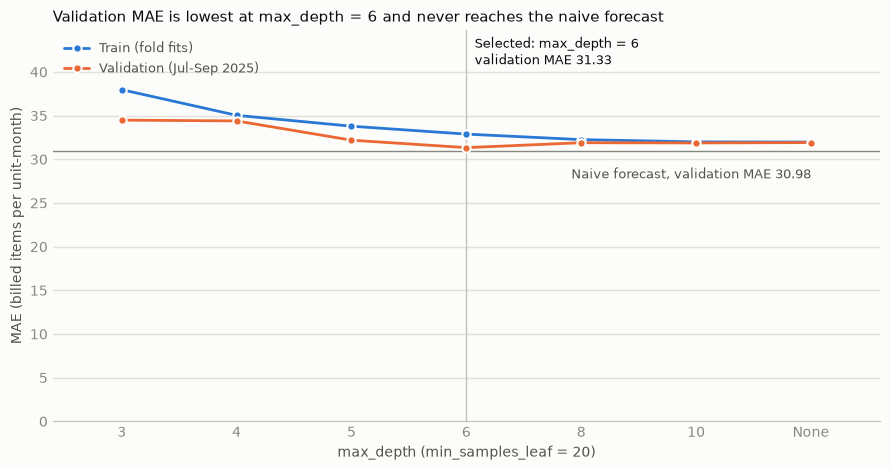

max_depth  train_MAE  val_MAE  mean_leaves
        3     37.970   34.481        7.000
        4     35.030   34.391       12.667
        5     33.786   32.184       20.667
        6     32.881   31.333       32.000
        8     32.249   31.896       59.667
       10     31.991   31.871       81.667
     None     31.969   31.911       88.333


In [10]:
# Light chart surface, text inks, and two categorical hues that stay distinguishable
# under colour-vision deficiency.
SURFACE, INK, INK_SECONDARY, MUTED, GRIDLINE, BASELINE = (
    "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7",
)
TRAIN_COLOR, VALIDATION_COLOR = "#2a78d6", "#eb6834"

curve = at_selected_alpha[at_selected_alpha["min_samples_leaf"].eq(selected_params["min_samples_leaf"])]
curve = curve.sort_values("depth_rank").reset_index(drop=True)
positions = np.arange(len(curve))
labels = [str(d) for d in curve["max_depth"]]
selected_position = labels.index(str(selected_params["max_depth"]))
last = positions[-1]
y_top = max(curve[["train_MAE", "val_MAE"]].to_numpy().max(), naive_cv_mae) * 1.18

fig, ax = plt.subplots(figsize=(9, 4.8), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
for column, color, label in [
    ("train_MAE", TRAIN_COLOR, "Train (fold fits)"),
    ("val_MAE", VALIDATION_COLOR, "Validation (Jul-Sep 2025)"),
]:
    ax.plot(positions, curve[column], color=color, linewidth=2, solid_joinstyle="round",
            solid_capstyle="round", marker="o", markersize=6, markeredgecolor=SURFACE,
            markeredgewidth=1.5, label=label, zorder=3)

ax.axhline(naive_cv_mae, color=MUTED, linewidth=1, zorder=2)
ax.annotate(f"Naive forecast, validation MAE {naive_cv_mae:,.2f}", (last, naive_cv_mae),
            xytext=(0, -12), textcoords="offset points", ha="right", va="top",
            color=INK_SECONDARY, fontsize=9)
ax.axvline(selected_position, color=BASELINE, linewidth=1, zorder=1)
ax.annotate(f"Selected: max_depth = {selected_params['max_depth']}\n"
            f"validation MAE {curve.loc[selected_position, 'val_MAE']:,.2f}",
            (selected_position, y_top), xytext=(6, -4), textcoords="offset points",
            va="top", color=INK, fontsize=9)

ax.set_xticks(positions, labels)
ax.set_xlim(-0.6, last + 0.6)
ax.set_ylim(0, y_top)
ax.set_xlabel(f"max_depth (min_samples_leaf = {selected_params['min_samples_leaf']})", color=INK_SECONDARY)
ax.set_ylabel("MAE (billed items per unit-month)", color=INK_SECONDARY)
beats_naive = bool((curve["val_MAE"] < naive_cv_mae).any())
ax.set_title(f"Validation MAE is lowest at max_depth = {selected_params['max_depth']}"
             + ("" if beats_naive else " and never reaches the naive forecast"),
             loc="left", color=INK, fontsize=11)
ax.grid(axis="y", color=GRIDLINE, linewidth=1)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(BASELINE)
ax.tick_params(colors=MUTED, length=0)
ax.legend(loc="upper left", frameon=False, labelcolor=INK_SECONDARY, fontsize=9)
fig.tight_layout()
fig.savefig(ASSETS / "decision-tree-depth-validation.png", dpi=150, bbox_inches="tight", facecolor=SURFACE)
plt.show()
print(curve[["max_depth", "train_MAE", "val_MAE", "mean_leaves"]].round(3).to_string(index=False))

**Result**: the figure, saved as `assets/decision-tree-depth-validation.png`,
shows the depth dimension at the selected leaf size. Validation MAE falls from 34.48 at depth 3
to its minimum of 31.33 at depth 6, then moves within a fifth of a point (31.90 at depth 8,
31.87 at depth 10, 31.91 unconstrained), and it stays above the naive line (30.98) at every
depth.

Training MAE falls at every level, from 37.97 to 31.97, but it does not collapse: with at least
20 rows per leaf the tree cannot memorize individual unit-months, and even without a depth limit
it grows only about 88 leaves at the selected pruning strength. The training curve lies *above*
the validation curve because the two score different months, not because the tree underfits: the
validation months carry more zero rows than the months fitted before them (Section 3), and zero
rows are the easiest to predict. The overfitting a depth limit exists to prevent appears only
when the leaf-size floor is removed as well; Section 7 measures it on the fully grown tree.

### 6.1 Grid-boundary check

Two findings of the search call for a look outside the registered grid: the selected
`min_samples_leaf` sits on the grid's lower edge, and the `ccp_alpha` values are too small to
prune the trees that matter. The check below extends both -- leaves of 1, 5 and 10 rows, pruning strengths of 1, 10 and
100 -- on the same folds. It is a robustness check on the verdict, not a new selection: the
registered grid is the contract shared with notebook 17 and Section 4.3.8, and changing it after
seeing the validation results would make the comparison between the candidates unequal.

In [11]:
BOUNDARY_GRID = {
    "max_depth": [4, 5, 6, 8, 10, None],
    "min_samples_leaf": [1, 5, 10],
    "ccp_alpha": [0.0, 1.0, 10.0, 100.0],
}
boundary = pd.DataFrame([
    cross_validate_tree({"max_depth": depth, "min_samples_leaf": leaf, "ccp_alpha": alpha})
    for depth in BOUNDARY_GRID["max_depth"]
    for leaf in BOUNDARY_GRID["min_samples_leaf"]
    for alpha in BOUNDARY_GRID["ccp_alpha"]
])
boundary["max_depth"] = pd.Series(
    [None if pd.isna(depth) else int(depth) for depth in boundary["max_depth"]], index=boundary.index, dtype=object
)
boundary["mean_leaves"] = boundary["leaves_per_fold"].map(np.mean)
best_boundary = boundary.sort_values(["val_MAE", "mean_leaves"], kind="stable").iloc[0]

print(f"{len(boundary)} configurations outside the registered grid. Five best:")
print(boundary.sort_values(["val_MAE", "mean_leaves"], kind="stable")[
    ["max_depth", "min_samples_leaf", "ccp_alpha", "val_MAE", "val_MAE_se", "mean_leaves"]
].head(5).round(3).to_string(index=False))
print(f"\nBest outside the grid: {best_boundary['val_MAE']:.3f} against {selected['val_MAE']:.3f} selected "
      f"({best_boundary['val_MAE'] - selected['val_MAE']:+.3f}; one standard error = {selected['val_MAE_se']:.3f})")
print(f"Naive forecast: {naive_cv_mae:.3f} -> configurations outside the grid below it: "
      f"{int((boundary['val_MAE'] < naive_cv_mae).sum())} of {len(boundary)}")

72 configurations outside the registered grid. Five best:
max_depth  min_samples_leaf  ccp_alpha  val_MAE  val_MAE_se  mean_leaves
        5                10        0.0   31.326       3.610       22.000
        5                10        1.0   31.326       3.610       22.000
        6                10        0.0   31.507       3.850       36.333
        6                10        1.0   31.589       3.905       34.667
        5                10       10.0   31.894       3.603       19.667

Best outside the grid: 31.326 against 31.333 selected (-0.007; one standard error = 3.142)
Naive forecast: 30.980 -> configurations outside the grid below it: 0 of 72


**Result**: the best configuration outside the grid, `max_depth = 5,
min_samples_leaf = 10`, reaches a validation MAE of **31.326**, 0.007 below the selected tree --
far inside one standard error (3.142), so three validation months cannot tell the two apart.
Stronger pruning does not help: `ccp_alpha = 1` leaves that tree unchanged and 10 already makes
it worse (31.894). **None of the 72 configurations reaches the naive forecast** either; the best
is still 1.1% above its 30.980. The verdict does not depend on where the grid's edges were
drawn.

### 6.2 What the search cost, and what its number is worth

Section 6 chose a configuration. This section asks two questions about the search itself: **what
it cost**, and **whether its best score is an honest estimate**.

- **Cost.** A search is priced in fits -- candidates x folds, plus the final refit. That figure is
  known before anything is launched, and it is what makes one extra hyperparameter expensive.
- **Resolution.** A grid spends its budget re-testing the values it was handed. Section 6 found
  that leaf size dominates and depth matters up to 6, yet the grid resolves those two axes with
  only 4 and 7 values, while `ccp_alpha`, which changes nothing here, multiplies the bill by 3. A
  **random search on the same budget**, drawing from continuous distributions, spends the same
  fits on distinct values instead (Bergstra and Bengio 2012). `min_samples_leaf` and `ccp_alpha`
  are drawn on a log scale because both are scale parameters: a uniform draw over 1-200 would put
  almost no mass on the small leaves Section 6.1 showed to matter.
- **Honesty.** `val_MAE.min()` is the minimum of 84 noisy estimates, so it is itself fitted to the
  validation months and biased downward. **Nested cross-validation** measures that bias: inner
  windows choose the configuration, and a month that took no part in the choice scores it.

Neither check is a re-selection. The registered grid is the contract shared with notebook 17 and
the configuration of Section 6 stands; both checks only report on it.


In [12]:
# A search is priced in fits: candidates x folds, plus the final refit on the whole training
# partition. The count is known before the search is launched.
N_CANDIDATES = int(np.prod([len(values) for values in PARAM_GRID.values()]))
print(f"Registered grid: {N_CANDIDATES} candidates x {len(cv_folds)} folds = "
      f"{N_CANDIDATES * len(cv_folds)} fits, plus one refit.")
print(f"One more hyperparameter with four values: {N_CANDIDATES * 4 * len(cv_folds):,} fits, "
      f"whether or not it changes a single prediction.")

# Random search on exactly that budget. min_samples_leaf and ccp_alpha are scale parameters, so
# they are drawn log-uniformly -- equal mass per order of magnitude. A uniform draw over 1-200
# would put almost no mass on the small leaves, and a uniform draw over the pruning range almost
# none below 1, while the selected tree's own pruning path starts at 0.4014.
RANDOM_SPACE = {
    "max_depth": randint(3, 21),             # integers, over the grid's depth range
    "min_samples_leaf": loguniform(1, 200),  # the grid's range, sampled on its own scale
    "ccp_alpha": loguniform(1e-3, 1e3),      # spans the selected tree's pruning path (0.4014)
}
rng = np.random.default_rng(RANDOM_STATE)
random_search = pd.DataFrame([
    cross_validate_tree({
        "max_depth": int(RANDOM_SPACE["max_depth"].rvs(random_state=rng)),
        "min_samples_leaf": int(round(float(RANDOM_SPACE["min_samples_leaf"].rvs(random_state=rng)))),
        "ccp_alpha": float(RANDOM_SPACE["ccp_alpha"].rvs(random_state=rng)),
    })
    for _ in range(N_CANDIDATES)
])
best_random = random_search.sort_values("val_MAE", kind="stable").iloc[0]

print(f"\nRandom search, {len(random_search)} draws on the same "
      f"{N_CANDIDATES * len(cv_folds)} fits. Five best:")
print(random_search.sort_values("val_MAE", kind="stable")[
    ["max_depth", "min_samples_leaf", "ccp_alpha", "val_MAE", "val_MAE_se"]
].head(5).round(4).to_string(index=False))
print("\nDistinct values each search actually explored:")
for name in ("max_depth", "min_samples_leaf", "ccp_alpha"):
    print(f"  {name}: grid {len(PARAM_GRID[name])}, random {random_search[name].nunique()}")
print(f"\nBest random draw {best_random['val_MAE']:.3f} against {selected['val_MAE']:.3f} selected "
      f"({best_random['val_MAE'] - selected['val_MAE']:+.3f}; "
      f"one standard error = {selected['val_MAE_se']:.3f})")
print(f"Naive forecast {naive_cv_mae:.3f} -> best random draw is "
      f"{(best_random['val_MAE'] / naive_cv_mae - 1) * 100:.1f}% above it; "
      f"random draws below it: {int((random_search['val_MAE'] < naive_cv_mae).sum())} "
      f"of {len(random_search)}")


Registered grid: 84 candidates x 3 folds = 252 fits, plus one refit.
One more hyperparameter with four values: 1,008 fits, whether or not it changes a single prediction.



Random search, 84 draws on the same 252 fits. Five best:
 max_depth  min_samples_leaf  ccp_alpha  val_MAE  val_MAE_se
         5                 8     0.0644  31.1343      3.6035
         7                11     0.0430  31.3405      3.4371
        14                15     0.0343  31.3791      3.6444
         5                 3     0.0685  31.4908      2.9241
         7                10     0.0013  31.4947      3.5074

Distinct values each search actually explored:
  max_depth: grid 7, random 18
  min_samples_leaf: grid 4, random 44
  ccp_alpha: grid 3, random 84

Best random draw 31.134 against 31.333 selected (-0.198; one standard error = 3.142)
Naive forecast 30.980 -> best random draw is 0.5% above it; random draws below it: 0 of 84


**Result**:

- **Cost.** The registered grid costs **252 fits** (84 candidates x 3 folds) plus one refit. One
  more hyperparameter with four values would cost **1,008**, four times as much, whether or not it
  changes a single prediction. That is the argument against widening a grid, and the argument for
  sampling inside one.
- **Resolution.** On the same 252 fits the random search explores **18 depths, 44 leaf sizes and
  84 pruning strengths**, against the grid's 7, 4 and 3. Its best draw -- `max_depth = 5,
  min_samples_leaf = 8, ccp_alpha = 0.0644` -- reaches validation MAE **31.134**, 0.198 below the
  selected tree and well inside one standard error (3.142), so three validation months cannot
  separate the two. It rediscovers by sampling what Section 6.1 found by extending the grid by
  hand: the improvement sits at leaf sizes below the grid's lower edge of 20. The pruning axis
  stays inert -- the five best draws span `ccp_alpha` from 0.0013 to 0.0685 with no ordering.
- **The verdict does not move.** The best random draw is still **0.5% above the naive forecast**
  (31.134 against 30.980), and **not one of the 84 draws reaches it**, as none of the 84 grid
  configurations and none of the 72 boundary configurations did. Three searches of different
  shapes agree: the gap is narrow, and no amount of tuning inside this family closes it.

In [13]:
# Nested cross-validation. The inner windows choose the configuration; an outer month that took
# no part in that choice scores it. This selects nothing -- it measures how much of the 31.333
# reported in Section 6 is the minimum of 84 noisy estimates rather than out-of-sample skill.
def mean_val_mae(params, folds):
    # Mean validation MAE over the folds given, clipped at zero exactly as `evaluate` clips.
    return float(np.mean([
        mean_absolute_error(
            y_train.iloc[val_rows],
            np.clip(DecisionTreeRegressor(random_state=RANDOM_STATE, **params)
                    .fit(X_train.iloc[fit_rows], y_train.iloc[fit_rows])
                    .predict(X_train.iloc[val_rows]), 0, None))
        for fit_rows, val_rows in folds
    ]))


month_index = [pd.Timestamp(month) for month in months]
nested = []
for outer_month in VALIDATION_MONTHS:
    # The two months before the outer one choose; the outer month only scores.
    position = month_index.index(outer_month)
    inner_months = month_index[position - 2:position]
    inner_folds = [(np.flatnonzero(train["MES"] < month), np.flatnonzero(train["MES"] == month))
                   for month in inner_months]
    inner_scores = {
        (depth, leaf, alpha): mean_val_mae(
            {"max_depth": depth, "min_samples_leaf": leaf, "ccp_alpha": alpha}, inner_folds)
        for depth in PARAM_GRID["max_depth"]
        for leaf in PARAM_GRID["min_samples_leaf"]
        for alpha in PARAM_GRID["ccp_alpha"]
    }
    (depth, leaf, alpha), inner_mae = min(inner_scores.items(), key=lambda item: item[1])
    inner_params = {"max_depth": depth, "min_samples_leaf": leaf, "ccp_alpha": alpha}
    outer_fold = [(np.flatnonzero(train["MES"] < outer_month),
                   np.flatnonzero(train["MES"] == outer_month))]
    nested.append({"outer_month": f"{outer_month:%Y-%m}",
                   "chosen_on": ",".join(f"{month:%b}" for month in inner_months),
                   **inner_params, "inner_MAE": inner_mae,
                   "outer_MAE": mean_val_mae(inner_params, outer_fold)})
nested = pd.DataFrame(nested)
nested_estimate = nested["outer_MAE"].mean()

print(f"{len(nested)} outer months x {N_CANDIDATES} candidates x 2 inner folds = "
      f"{len(nested) * N_CANDIDATES * 2} fits.")
print(nested.round(3).to_string(index=False))
print(f"\nNested estimate (mean over the outer months): {nested_estimate:.3f}")
print(f"Non-nested minimum reported in Section 6:      {selected['val_MAE']:.3f}")
print(f"Optimism of the non-nested number: {selected['val_MAE'] - nested_estimate:+.3f} "
      f"(one standard error = {selected['val_MAE_se']:.3f})")


3 outer months x 84 candidates x 2 inner folds = 504 fits.
outer_month chosen_on  max_depth  min_samples_leaf  ccp_alpha  inner_MAE  outer_MAE
    2025-07   May,Jun        NaN                20      0.001     38.975     36.422
    2025-08   Jun,Jul        4.0                20      0.000     37.801     35.777
    2025-09   Jul,Aug        5.0                20      0.000     34.330     27.892

Nested estimate (mean over the outer months): 33.364
Non-nested minimum reported in Section 6:      31.333
Optimism of the non-nested number: -2.031 (one standard error = 3.142)


**Result**: the three outer months do **not** agree on a configuration. The inner windows select
`max_depth = None` for July, `max_depth = 4` for August and `max_depth = 5` for September, all
three at `min_samples_leaf = 20`. The nested estimate, the mean of those three genuinely
out-of-sample scores, is **33.364** against the non-nested minimum of **31.333**, so the figure
reported in Section 6 is optimistic by **2.031** -- real, but inside one standard error (3.142)
of the fold-to-fold noise.

The bias is bounded for a structural reason: the 84 candidates cover only 28 distinct
`max_depth x min_samples_leaf` pairs, and `ccp_alpha` leaves 15 of those 28 unchanged
(Section 6), so the search is smaller than its candidate count suggests and its objective is flat
near the minimum. The practical consequence is that **31.333 is a reasonable, if slightly
optimistic, estimate of out-of-sample performance**, and the conclusion drawn from it -- that the
tree does not quite reach the naive forecast's 30.980 in validation -- survives the correction,
since even the nested estimate sits on the same side of that bar.

The inner windows are two months rather than three and sit earlier in the panel, where the zero
share is lower and volumes higher, so their own MAEs (38.975, 37.801, 34.330) are larger than the
outer ones (36.422, 35.777, 27.892) and are not comparable with Section 6; only the `outer_MAE`
column is.

## 7. Final Fit and Test Evaluation

The selected configuration is refitted on every February-September row and scored once on
October-December, next to the two baselines. The unconstrained tree (`max_depth = None`,
`min_samples_leaf = 1`, no pruning) is fitted on the same rows and reported beside it -- not as
a competitor, but to measure what the regularization buys. Neither result feeds back into the
choice of configuration, which was fixed in Section 6. The second cell reconciles the results
with the tables published in Section 4.3.8.4.

In [14]:
final_tree = DecisionTreeRegressor(random_state=RANDOM_STATE, **selected_params).fit(X_train, y_train)
unconstrained_tree = DecisionTreeRegressor(random_state=RANDOM_STATE).fit(X_train, y_train)
observed_test = ~test["IS_STRUCTURAL_ZERO"].to_numpy()

test_predictions = {
    "Naive baseline (last month)": naive_forecast(test),
    "Group-mean baseline": group_mean_forecast(train, test),
    "Decision tree (selected)": final_tree.predict(X_test),
    f"Decision tree (unconstrained, depth {unconstrained_tree.get_depth()})": unconstrained_tree.predict(X_test),
}
naive_test_mae = {
    "all rows": evaluate(y_test, test_predictions["Naive baseline (last month)"])["MAE"],
    "observed rows": evaluate(y_test, test_predictions["Naive baseline (last month)"], observed_test)["MAE"],
}
test_results = pd.DataFrame([
    {"row_set": row_set, "model": name,
     **evaluate(y_test, pred, None if row_set == "all rows" else observed_test, naive_test_mae[row_set])}
    for row_set in ("all rows", "observed rows")
    for name, pred in test_predictions.items()
])

print(f"Selected tree: {selected_params} -> depth {final_tree.get_depth()}, {final_tree.get_n_leaves()} leaves")
print(f"Unconstrained tree: depth {unconstrained_tree.get_depth()}, {unconstrained_tree.get_n_leaves():,} leaves")
print(f"Training MAE (Feb-Sep): selected {mean_absolute_error(y_train, final_tree.predict(X_train)):.3f} | "
      f"unconstrained {mean_absolute_error(y_train, unconstrained_tree.predict(X_train)):.3f}\n")
for row_set, block in test_results.groupby("row_set", sort=False):
    print(f"Test, {row_set} (n = {block['rows'].iloc[0]:,}):")
    print(block.drop(columns=["row_set", "rows"]).round(3).to_string(index=False), "\n")

Selected tree: {'max_depth': 6, 'min_samples_leaf': 20, 'ccp_alpha': 0.01} -> depth 6, 36 leaves
Unconstrained tree: depth 33, 3,863 leaves
Training MAE (Feb-Sep): selected 29.373 | unconstrained 1.634

Test, all rows (n = 3,810):
                                  model    MAE    RMSE     R2  MAE_log1p  VOLUME_RATIO  SKILL_VS_NAIVE
            Naive baseline (last month) 19.724  74.895  0.611      0.522         1.043           0.000
                    Group-mean baseline 31.126 128.766 -0.149      0.859         1.670          -0.578
               Decision tree (selected) 19.065  89.590  0.444      0.726         1.018           0.033
Decision tree (unconstrained, depth 33) 26.931 182.523 -1.309      0.677         0.993          -0.365 

Test, observed rows (n = 1,674):
                                  model    MAE    RMSE    R2  MAE_log1p  VOLUME_RATIO  SKILL_VS_NAIVE
            Naive baseline (last month) 38.216 108.679 0.605      0.701         0.951           0.000
               

In [15]:
# Reconciliation gate against documentation Section 4.3.8.4 (MAE, RMSE, R2,
# MAE on log1p, skill vs naive; three decimals, as printed there). Notebook 17 refits this
# tree independently, so a match means both notebooks and the documentation agree.
SECTION_4_3_8 = {
    ("all rows", "Naive baseline (last month)"): (19.724, 74.895, 0.611, 0.522, 0.000),
    ("all rows", "Group-mean baseline"): (31.126, 128.766, -0.149, 0.859, -0.578),
    ("all rows", "Decision tree (selected)"): (19.065, 89.590, 0.444, 0.726, 0.033),
    ("observed rows", "Naive baseline (last month)"): (38.216, 108.679, 0.605, 0.701, 0.000),
    ("observed rows", "Group-mean baseline"): (44.455, 124.514, 0.481, 0.568, -0.163),
    ("observed rows", "Decision tree (selected)"): (31.806, 97.197, 0.684, 0.465, 0.168),
}
METRICS = ["MAE", "RMSE", "R2", "MAE_log1p", "SKILL_VS_NAIVE"]
reconciliation = []
for (row_set, model), published in SECTION_4_3_8.items():
    computed = test_results.loc[test_results["row_set"].eq(row_set) & test_results["model"].eq(model), METRICS].iloc[0]
    for metric, value in zip(METRICS, published):
        reconciliation.append({"row_set": row_set, "model": model, "metric": metric, "published": value,
                               "computed": round(float(computed[metric]), 3) + 0.0})
reconciliation = pd.DataFrame(reconciliation)
reconciliation["matches"] = np.isclose(reconciliation["published"], reconciliation["computed"], rtol=0, atol=5e-4)
print(f"Figures reproduced: {reconciliation['matches'].sum()} of {len(reconciliation)}")
mismatches = reconciliation[~reconciliation["matches"]]
print("Mismatches:" if len(mismatches) else "No mismatch with Section 4.3.8.4.")
if len(mismatches):
    print(mismatches.to_string(index=False))
# A gate, not a report: if the documentation and this notebook ever drift apart again, the
# pipeline has to fail here instead of printing the disagreement and moving on.
assert reconciliation["matches"].all(), (
    "documentation Section 4.3.8.4 and this notebook disagree -- update whichever one is stale"
)

Figures reproduced: 30 of 30
No mismatch with Section 4.3.8.4.


**Result**: the selected tree has **depth 6 and 36 leaves**; the unconstrained
tree reaches **depth 33 with 3,863 leaves**.

| Row set | Model | MAE | RMSE | R2 | MAE (log1p) | VOLUME_RATIO | Skill vs naive |
|---|---|---|---|---|---|---|---|
| All rows (3,810) | Naive baseline | 19.724 | **74.895** | **0.611** | **0.522** | 1.043 | 0.000 |
| | Group-mean baseline | 31.126 | 128.766 | -0.149 | 0.859 | 1.670 | -0.578 |
| | Decision tree, selected | **19.065** | 89.590 | 0.444 | 0.726 | 1.018 | **+0.033** |
| | Decision tree, unconstrained | 26.931 | 182.523 | -1.309 | 0.677 | 0.993 | -0.365 |
| Observed rows (1,674) | Naive baseline | 38.216 | 108.679 | 0.605 | 0.701 | 0.951 | 0.000 |
| | Group-mean baseline | 44.455 | 124.514 | 0.481 | 0.568 | 1.307 | -0.163 |
| | Decision tree, selected | **31.806** | **97.197** | **0.684** | **0.465** | 0.858 | **+0.168** |
| | Decision tree, unconstrained | 45.960 | 129.174 | 0.441 | 0.942 | 0.782 | -0.203 |

**The regularization does what it was chosen for.** The unconstrained tree memorizes the
training months (training MAE 1.634) and fails on the test (26.931); the selected tree keeps its
training MAE at 29.373, lowers test MAE by 29.2% against the unconstrained tree and raises R2
from -1.309 to 0.444. Its test MAE is below its training MAE mainly because the test months hold
more zero rows (Section 3).

**Unlike the full-population run, the tree beats the naive forecast on both row sets.** On all
rows it edges ahead on MAE (19.065 against 19.724, skill +0.033) while losing on RMSE (89.590
against 74.895) and R2 (0.444 against 0.611), because the squared-error metrics still reward the
naive forecast's exact zeros over the tree's smallest leaf prediction. On observed rows it leads
on **every** metric: MAE (31.806 against 38.216), RMSE (97.197 against 108.679), R2 (0.684
against 0.605) and `log1p` MAE (0.465 against 0.701), for a skill of +0.168. The relative
measure is the widest gap, and the reason is that it punishes predicting zero for a unit that did
bill: the naive forecast does that on 22.0% of the observed test rows, whenever last month was
quiet, and the tree, whose smallest prediction is 0.766, never does (Section 7.1).

**The figures reconcile with Section 4.3.8.4**: the cell above asserts all 30 published values
against the ones computed here, to the third decimal, and notebook 17, which refits this tree
independently, prints the same numbers.

### 7.1 Test error by month, by provider state and by row kind

Three breakdowns of the test error, for the selected tree and the naive forecast:

- **By month**, to separate October from the two months affected by reporting lag.
- **By `UF_PRESTADOR`**, as Section 4.2.1 asks of model validation. That section asks for it
  because Para alone carries about half of all events in the full treated base; on this
  Medicina de Grupo population the volume concentrates in Amazonas instead, as the result
  below shows. `WAPE` is the total absolute error as a share of the
  observed volume. Section 4.2.1 also asks for a breakdown by age group; the matrix grain has no
  age dimension, so it cannot be provided here.
- **By row kind**: observed rows against the structural zeros of Section 2.2.
  `scripts/diagnose_modeling_matrix.py` warns that a model scored on that zero mass is partly
  scoring the reindex. The split conditions on the true target, so it is an error diagnostic
  only, never an input to the model or to the choice of configuration.

In [16]:
test_eval = test[["MES", "UF_PRESTADOR", TARGET, "IS_STRUCTURAL_ZERO", "DEMAND_LAG_1M"]].copy()
test_eval["tree"] = np.clip(final_tree.predict(X_test), 0, None)
test_eval["naive"] = naive_forecast(test)

by_month = []
for month, group in test_eval.groupby("MES"):
    naive_mae = mean_absolute_error(group[TARGET], group["naive"])
    by_month.append({
        "month": f"{month:%Y-%m}", "rows": len(group), "zero_share_pct": group[TARGET].eq(0).mean() * 100,
        "observed_volume": group[TARGET].sum(),
        "tree_MAE": mean_absolute_error(group[TARGET], group["tree"]), "naive_MAE": naive_mae,
        "tree_skill": 1 - mean_absolute_error(group[TARGET], group["tree"]) / naive_mae,
        "tree_VOLUME_RATIO": group["tree"].sum() / group[TARGET].sum(),
        "naive_VOLUME_RATIO": group["naive"].sum() / group[TARGET].sum(),
    })
print(pd.DataFrame(by_month).round(3).to_string(index=False))

  month  rows  zero_share_pct  observed_volume  tree_MAE  naive_MAE  tree_skill  tree_VOLUME_RATIO  naive_VOLUME_RATIO
2025-10  1217          52.917          48472.0    21.361     21.048      -0.015              0.936               0.770
2025-11  1279          54.652          38794.0    20.453     22.339       0.084              1.083               1.294
2025-12  1314          60.350          34443.0    15.588     15.952       0.023              1.058               1.144


In [17]:
by_state = []
for state, group in test_eval.groupby("UF_PRESTADOR", observed=True):
    observed = group[TARGET]
    by_state.append({
        "UF_PRESTADOR": state, "rows": len(group),
        "share_of_test_volume_pct": observed.sum() / test_eval[TARGET].sum() * 100,
        "tree_MAE": mean_absolute_error(observed, group["tree"]),
        "naive_MAE": mean_absolute_error(observed, group["naive"]),
        "tree_WAPE_pct": (group["tree"] - observed).abs().sum() / observed.sum() * 100,
        "naive_WAPE_pct": (group["naive"] - observed).abs().sum() / observed.sum() * 100,
        "tree_VOLUME_RATIO": group["tree"].sum() / observed.sum(),
    })
by_state = pd.DataFrame(by_state).sort_values("share_of_test_volume_pct", ascending=False)
print(by_state.round(3).to_string(index=False))

UF_PRESTADOR  rows  share_of_test_volume_pct  tree_MAE  naive_MAE  tree_WAPE_pct  naive_WAPE_pct  tree_VOLUME_RATIO
          AM  1795                    95.130    38.360     40.160         59.471          62.261              1.010
          PA  1158                     4.497     2.398      2.224         50.728          47.049              1.051
          RO   272                     0.159     1.842      0.746        258.274         104.639              3.313
          TO   245                     0.107     0.867      0.457        163.413          86.154              1.810
          AP   237                     0.098     0.869      0.612        173.128         121.849              1.877
          AC    40                     0.008     0.960      0.475        384.133         190.000              4.433
          RR    63                     0.001     0.757      0.095       4770.651         600.000             48.238


In [18]:
row_kind = np.where(test_eval["IS_STRUCTURAL_ZERO"], "structural zero", "observed")
total_error = {model: (test_eval[model] - test_eval[TARGET]).abs().sum() for model in ("tree", "naive")}
by_row_kind = []
for kind, group in test_eval.groupby(row_kind):
    for model in ("tree", "naive"):
        error = (group[model] - group[TARGET]).abs()
        by_row_kind.append({
            "row_kind": kind, "model": model, "rows": len(group),
            "mean_observed": group[TARGET].mean(), "mean_predicted": group[model].mean(),
            "MAE": error.mean(), "median_abs_error": error.median(),
            "share_of_model_total_error_pct": error.sum() / total_error[model] * 100,
        })
print(pd.DataFrame(by_row_kind).round(3).to_string(index=False))

print(f"\nSmallest value the selected tree can predict (its lowest leaf mean): "
      f"{final_tree.tree_.value[final_tree.tree_.children_left == -1].min():.3f}")
zero_rows = test_eval[test_eval["IS_STRUCTURAL_ZERO"]]
observed_rows = test_eval[~test_eval["IS_STRUCTURAL_ZERO"]]
print(f"Test rows where the naive forecast is exactly 0: structural zeros {zero_rows['naive'].eq(0).mean() * 100:.1f}% "
      f"| observed rows {observed_rows['naive'].eq(0).mean() * 100:.1f}%")
for kind, group in test_eval.groupby(row_kind):
    excess = ((group["tree"] - group[TARGET]).abs() - (group["naive"] - group[TARGET]).abs()).sum()
    print(f"Tree minus naive total absolute error, {kind} rows: {excess:+,.0f}")

       row_kind model  rows  mean_observed  mean_predicted    MAE  median_abs_error  share_of_model_total_error_pct
       observed  tree  1674         72.705          62.393 31.806             2.661                          73.300
       observed naive  1674         72.705          69.163 38.216             2.000                          85.132
structural zero  tree  2136          0.000           9.080  9.080             0.766                          26.700
structural zero naive  2136          0.000           5.231  5.231             0.000                          14.868

Smallest value the selected tree can predict (its lowest leaf mean): 0.766
Test rows where the naive forecast is exactly 0: structural zeros 75.2% | observed rows 22.0%
Tree minus naive total absolute error, observed rows: -10,730
Tree minus naive total absolute error, structural zero rows: +8,221


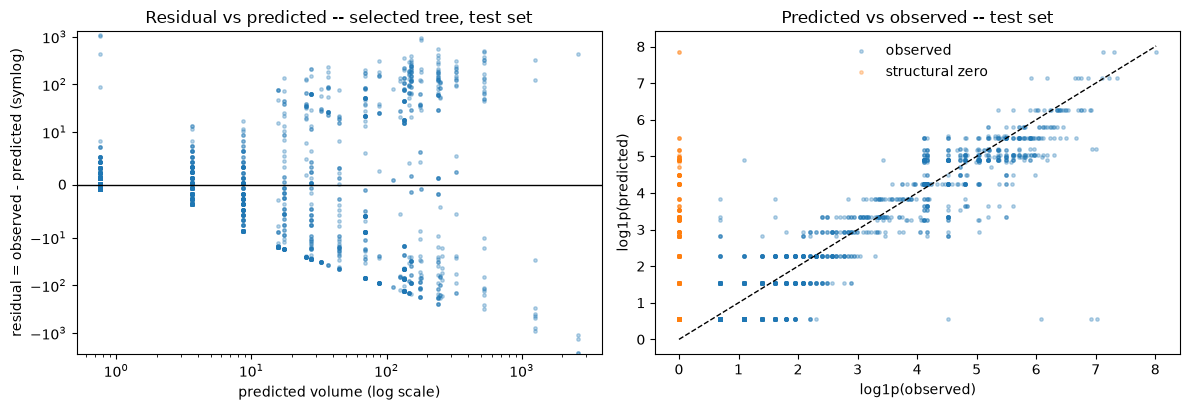

In [19]:
# One vertical stripe per leaf: the tree predicts a constant per leaf, so the spread inside a
# stripe is what it cannot resolve. Log scales, because the target spans five orders of magnitude.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
residual = test_eval[TARGET] - test_eval["tree"]
axes[0].scatter(test_eval["tree"], residual, s=6, alpha=0.3)
axes[0].axhline(0, color="k", lw=1)
axes[0].set_xscale("log")
axes[0].set_yscale("symlog", linthresh=10)
axes[0].set(xlabel="predicted volume (log scale)", ylabel="residual = observed - predicted (symlog)",
            title="Residual vs predicted -- selected tree, test set")
for flag, label in [(False, "observed"), (True, "structural zero")]:
    subset = test_eval[test_eval["IS_STRUCTURAL_ZERO"].eq(flag)]
    axes[1].scatter(np.log1p(subset[TARGET]), np.log1p(subset["tree"]), s=6, alpha=0.3, label=label)
limit = float(np.log1p(test_eval[[TARGET, "tree"]].to_numpy().max()))
axes[1].plot([0, limit], [0, limit], "k--", lw=1)
axes[1].set(xlabel="log1p(observed)", ylabel="log1p(predicted)", title="Predicted vs observed -- test set")
axes[1].legend(frameon=False)
fig.tight_layout()
plt.show()

**Result**:

- **By month, the tree loses to the naive forecast only in October** (skill -0.015, tree MAE
  21.361 against 21.048) and wins in November (+0.084, 20.453 against 22.339) and December
  (+0.023, 15.588 against 15.952), so the overall result does not hinge on the two incomplete
  months. The reporting lag shows in the totals: observed volume falls from 48,472 (October) to
  38,794 (November) and 34,443 (December). Both forecasts overstate November and December (tree
  volume ratio 1.083 and 1.058, naive 1.294 and 1.144) while understating October (0.936 and
  0.770), with the tree closer to 1.0 in every month.
- **By state, the tree's MAE is higher than the naive forecast's in six of the seven states, and
  lower in the one that carries the volume.** Amazonas holds 95.1% of the test volume, and there
  the tree leads on both MAE (38.360 against 40.160) and WAPE (59.5% against 62.3%). It loses
  narrowly in Para (4.5% of volume, 2.398 against 2.224) and by wide relative margins in the five
  states that together carry 0.4% of the volume, where a handful of rows make WAPE unstable
  (Roraima: 63 rows, tree WAPE 4,770.7% against the naive forecast's 600.0%). That pattern is
  consistent with leaves that pool units from every state: a small state's units receive means
  shaped largely by larger ones.
- **By row kind, the structural zeros are what the tree pays for its observed-row gain.** On the
  2,136 structural-zero rows (56.1% of the test set) it predicts 9.080 on average, against 5.231
  for the naive forecast, which is exactly 0 on 75.2% of them. The tree cannot predict 0: its
  smallest leaf predicts **0.766**, so every zero row costs it at least that much, and its median
  error on those rows is 0.766 against 0. That costs it 8,221 items of extra absolute error
  there, while on the 1,674 observed rows it saves 10,730 items against the naive forecast. The
  two net to the small overall win, which is the mean-versus-median trade noted in Section 4: a
  squared-error leaf predicts the mean of a group that is mostly zeros, while MAE rewards its
  median, which is zero.

The residual plot shows the same structure: one vertical stripe per leaf, with the low-volume
leaves overpredicting the zero rows (the structural zeros sit on the left edge of the
predicted-versus-observed panel) and the spread inside the high-volume stripes reaching hundreds
of items in either direction.

## 8. Fitted Tree

The selected tree is the project's **explanatory** artifact (Sections 4.3.8.7 and 4.3.10.5): Risk R05
requires that the partner can follow the reasoning in plain language, and a few levels of a
single tree do that in a way a 600-tree forest cannot. The figure shows its first three levels of
splits, with the share of training rows and the mean volume in each node, and is saved as
`assets/decision-tree-top-levels.png`. The tables below it describe the leaves -- training rows,
predicted volume, and how the test rows that reach each leaf behave -- and give the rules of the
largest ones. A condition is marked "(or missing)" when rows with a missing value for that
feature also reach the leaf.

Depth 6, 36 leaves. Training rows per leaf: min 20, median 40, max 4,225
Five largest leaves hold 78.8% of the training rows; leaves predicting under 10 items hold 72.6%
Leaf predictions range from 0.77 to 2,591.90


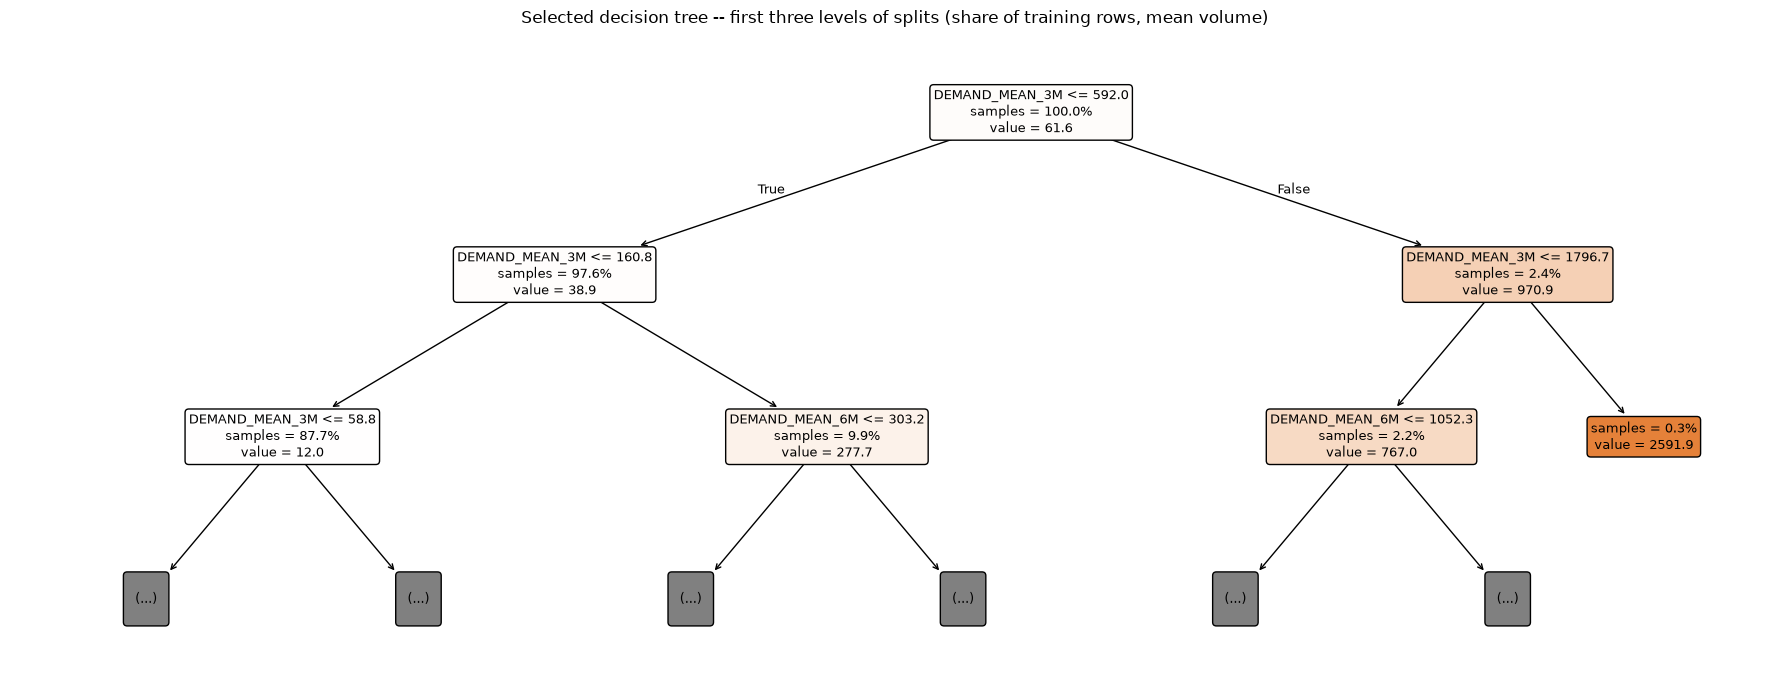

In [20]:
leaf_ids = np.flatnonzero(final_tree.tree_.children_left == -1)
leaf_train_rows = pd.Series(final_tree.tree_.n_node_samples[leaf_ids], index=leaf_ids)
leaf_prediction = pd.Series(final_tree.tree_.value[leaf_ids].ravel(), index=leaf_ids)
print(f"Depth {final_tree.get_depth()}, {len(leaf_ids)} leaves. Training rows per leaf: min {leaf_train_rows.min()}, "
      f"median {leaf_train_rows.median():.0f}, max {leaf_train_rows.max():,}")
print(f"Five largest leaves hold {leaf_train_rows.nlargest(5).sum() / len(train) * 100:.1f}% of the training rows; "
      f"leaves predicting under 10 items hold {leaf_train_rows[leaf_prediction < 10].sum() / len(train) * 100:.1f}%")
print(f"Leaf predictions range from {leaf_prediction.min():.2f} to {leaf_prediction.max():,.2f}")

fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(final_tree, max_depth=2, feature_names=X_COLUMNS, filled=True, impurity=False,
          proportion=True, precision=1, rounded=True, fontsize=9, ax=ax)
ax.set_title("Selected decision tree -- first three levels of splits (share of training rows, mean volume)")
fig.tight_layout()
fig.savefig(ASSETS / "decision-tree-top-levels.png", dpi=150, bbox_inches="tight")
plt.show()

In [21]:
def leaf_rules(tree, feature_names, X_reference):
    # One readable rule per leaf. Successive conditions on the same feature are collapsed to
    # its tightest bounds; "(or missing)" marks a feature whose missing values also reach the
    # leaf, given the side sklearn routes them to at each split.
    structure = tree.tree_
    has_missing = X_reference.isna().any()
    rules = {}

    def walk(node, bounds):
        if structure.children_left[node] == -1:
            parts = []
            for name, (low, high, missing_ok) in bounds.items():
                text = (f"{low:,.1f} < {name} <= {high:,.1f}" if low > -np.inf and high < np.inf
                        else f"{name} <= {high:,.1f}" if high < np.inf else f"{name} > {low:,.1f}")
                parts.append(text + (" (or missing)" if missing_ok and has_missing[name] else ""))
            rules[node] = " AND ".join(parts)
            return
        name = feature_names[structure.feature[node]]
        threshold = structure.threshold[node]
        missing_left = bool(structure.missing_go_to_left[node])
        low, high, missing_ok = bounds.get(name, (-np.inf, np.inf, True))
        walk(structure.children_left[node], {**bounds, name: (low, min(high, threshold), missing_ok and missing_left)})
        walk(structure.children_right[node], {**bounds, name: (max(low, threshold), high, missing_ok and not missing_left)})

    walk(0, {})
    return pd.Series(rules)


rules = leaf_rules(final_tree, X_COLUMNS, X_train)
test_leaf = final_tree.apply(X_test)
leaves = pd.DataFrame({
    "train_rows": leaf_train_rows,
    "train_share_pct": leaf_train_rows / len(train) * 100,
    "predicted_volume": leaf_prediction,
}).join(
    test_eval.assign(leaf=test_leaf).groupby("leaf").agg(
        test_rows=(TARGET, "size"), test_mean_observed=(TARGET, "mean"),
        test_structural_zero_pct=("IS_STRUCTURAL_ZERO", lambda s: s.mean() * 100))
).fillna({"test_rows": 0}).astype({"test_rows": int}).rename_axis("leaf")
assert leaves["train_rows"].sum() == len(train) and leaves["test_rows"].sum() == len(test)

reached = leaves[leaves["test_rows"] > 0]
leaf_corr = np.corrcoef(np.log1p(reached["predicted_volume"]), np.log1p(reached["test_mean_observed"]))[0, 1]
print(f"Leaves reached by test rows: {len(reached)} of {len(leaves)}; correlation of log1p(leaf prediction) "
      f"with log1p(observed test mean) across them: {leaf_corr:.3f}\n")

pd.set_option("display.max_colwidth", None)
print("The eight largest leaves (by training rows):")
print(leaves.sort_values("train_rows", ascending=False).head(8).round(2).to_string())
print("\nTheir rules:")
for leaf in leaves.sort_values("train_rows", ascending=False).head(8).index:
    print(f"  leaf {leaf}: {rules[leaf]}")
print("\nThe five highest-volume leaves:")
print(leaves.sort_values("predicted_volume", ascending=False).head(5).round(2).to_string())

importances = pd.Series(final_tree.feature_importances_, index=X_COLUMNS, name="impurity_importance")
print("\nImpurity-based feature importance:")
print(importances.sort_values(ascending=False).round(4).to_string())

Leaves reached by test rows: 26 of 36; correlation of log1p(leaf prediction) with log1p(observed test mean) across them: 0.973

The eight largest leaves (by training rows):
      train_rows  train_share_pct  predicted_volume  test_rows  test_mean_observed  test_structural_zero_pct
leaf                                                                                                        
6           4225            54.76              0.77       2444                1.54                     75.20
7            961            12.45              3.66        332                3.13                     18.07
10           412             5.34              8.68        180                6.11                     22.22
22           258             3.34             68.93        100               69.61                     20.00
30           227             2.94            134.84        118               98.47                     26.27
13           174             2.26             17.54         70  

**Result**: the tree is, in practice, a sorter of units by recent volume, and it sorts almost
entirely on one feature.

- **Every split that matters is on a rolling mean.** The rules of the eight largest leaves are
  built from `DEMAND_MEAN_3M` and `DEMAND_MEAN_6M`, with `DEMAND_LAG_3M`, `DEMAND_LAG_6M`,
  `DEMAND_STD_3M` and `PORTE_ORDINAL` appearing only as later refinements inside the
  higher-volume branches. Read top-down, the tree says what the whole model says: units that
  billed a lot recently are expected to bill a lot next month.
- **A few low-volume leaves hold most of the data.** The five largest leaves hold 78.8% of the
  training rows, and leaves predicting under 10 items hold 72.6%. The largest, leaf 6 (4,225
  rows, 54.76%), gathers units whose recent history is near zero (`DEMAND_MEAN_3M <= 2.4` and
  `DEMAND_MEAN_6M <= 5.5 or missing`) and predicts **0.77**, the tree's smallest prediction. It
  receives 2,444 of the 3,810 test rows, 75.2% of them structural zeros, with an observed mean
  of 1.54.
- **The high-volume tail is thin but well ordered.** Leaf predictions range from 0.77 to
  2,591.90 across the tree's 36 leaves; the five highest-volume leaves hold 21 to 63 training
  rows each, and only two of them receive any test row at all. Across the 26 leaves the test
  does reach, the correlation between a leaf's prediction and the test mean it observes is 0.973
  on the `log1p` scale: the ordering of units carries over to October-December.
- **`MONTH` enters only through splits the test months never cross.** It takes 2.0% of the
  impurity but its permutation importance on the test set is exactly 0 with zero variance
  (Section 8.1), so no split on it separates October, November and December.

**Feature importance**: by impurity, `DEMAND_MEAN_3M` (0.9206) and `DEMAND_MEAN_6M` (0.0402)
account for 96.1% of the reduction in squared error, and the other six predictors share the
remaining 3.9%. `DEMAND_LAG_1M`, which was the second-most-important feature on the full
population, is reduced to 0.0009 here. These are the values notebook 17 reports for the same
tree (Section 4.3.10.4).

### 8.1 Permutation importance and partial dependence

Impurity importance measures what the *fitted* tree used on the training rows. Two model-agnostic
views are added on the **test** set, where over- or under-use shows up as real error:

- **Permutation importance** -- the rise in test MAE when one predictor's values are shuffled
  (ten repeats). A feature the model relies on gets a large positive value; one it ignores sits at
  zero, and noise can go slightly negative.
- **Partial dependence** for the two predictors with the highest permutation importance, on a
  shared axis, to show the shape of each effect over the central 90% of the data.

                impurity_importance  permutation_importance  permutation_std
DEMAND_MEAN_3M               0.9206                 33.5718           0.5958
DEMAND_MEAN_6M               0.0402                  2.2973           0.0937
DEMAND_LAG_3M                0.0108                  0.8825           0.0871
DEMAND_STD_3M                0.0063                  0.2280           0.0434
MONTH                        0.0197                  0.0000           0.0000
DEMAND_LAG_1M                0.0009                  0.0000           0.0000
PORTE_ORDINAL                0.0005                 -0.0662           0.0541
DEMAND_LAG_6M                0.0010                 -0.2023           0.0771


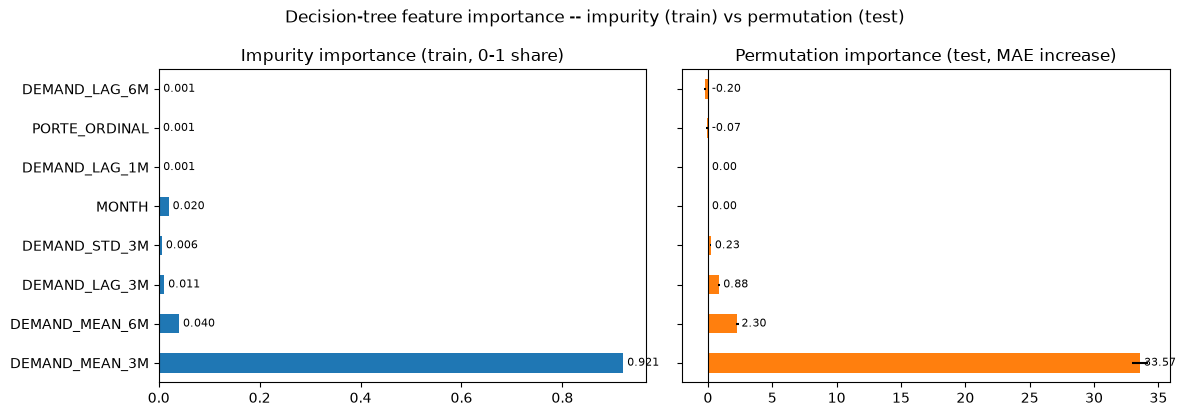

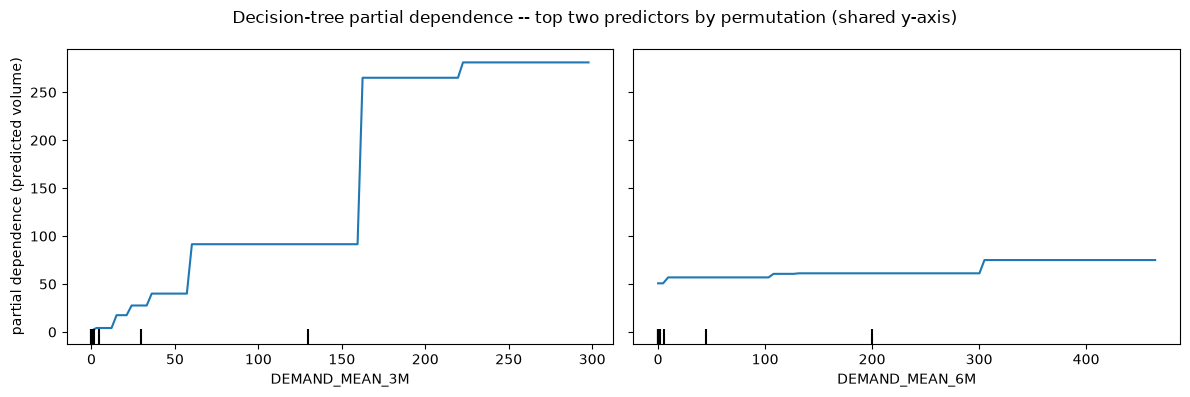

In [22]:
perm = permutation_importance(
    final_tree, X_test, y_test, n_repeats=10,
    random_state=RANDOM_STATE, scoring="neg_mean_absolute_error",
)
attribution = pd.DataFrame({
    "impurity_importance": importances,
    "permutation_importance": pd.Series(perm.importances_mean, index=X_COLUMNS),
    "permutation_std": pd.Series(perm.importances_std, index=X_COLUMNS),
}).sort_values("permutation_importance", ascending=False)
print(attribution.round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
attribution["impurity_importance"].plot.barh(ax=axes[0], color="tab:blue")
axes[0].set(title="Impurity importance (train, 0-1 share)", xlabel="", ylabel="")
axes[0].invert_yaxis()
for y, v in enumerate(attribution["impurity_importance"]):
    axes[0].text(v, y, f" {v:.3f}", va="center", fontsize=8)
attribution["permutation_importance"].plot.barh(ax=axes[1], color="tab:orange",
                                                 xerr=attribution["permutation_std"])
axes[1].set(title="Permutation importance (test, MAE increase)", xlabel="", ylabel="")
axes[1].axvline(0, color="k", lw=0.8)
for y, v in enumerate(attribution["permutation_importance"]):
    axes[1].text(max(v, 0), y, f" {v:.2f}", va="center", fontsize=8)
fig.suptitle("Decision-tree feature importance -- impurity (train) vs permutation (test)")
fig.tight_layout()
fig.savefig(ASSETS / "decision-tree-feature-importance.png", dpi=150, bbox_inches="tight")
plt.show()

top2 = attribution.index[:2].tolist()
fig, axes = plt.subplots(1, len(top2), figsize=(6 * len(top2), 4), sharey=True)
PartialDependenceDisplay.from_estimator(final_tree, X_test, top2, ax=axes)
axes[0].set_ylabel("partial dependence (predicted volume)")
axes[1].set_ylabel("")
fig.suptitle("Decision-tree partial dependence -- top two predictors by permutation (shared y-axis)")
fig.tight_layout()
plt.show()

**Result**: the two views agree on the leader and disagree on the rest. Shuffling
`DEMAND_MEAN_3M` raises the test MAE by **33.57** and `DEMAND_MEAN_6M` by **2.30**;
`DEMAND_LAG_3M` follows at 0.88 and every other predictor stays under 0.25. `MONTH` and
`DEMAND_LAG_1M` both score exactly 0 with zero variance -- the fitted tree never splits on
either -- and `PORTE_ORDINAL` and `DEMAND_LAG_6M` score slightly below zero, noise. The tree is
an autoregressor on recent demand, the same reading Section 4.3.9.6 gives for the forest.

The single tree commits to `DEMAND_MEAN_3M` at the root and credits the correlated encodings
much less; the forest spreads the same signal over `DEMAND_MEAN_3M` and `DEMAND_MEAN_6M`
(22.31 and 7.92 MAE points there, Section 4.3.9.6). That concentration is a property of one
greedy split sequence, not evidence that the three-month mean carries all the information. The
partial-dependence curves show the same thing: over the central range of the data, predicted
volume climbs in steps with `DEMAND_MEAN_3M`, while `DEMAND_LAG_1M` does not move it at all.

## 9. Leakage Sanity Check

Section 2.1 audited the data: every row and every feature value was knowable at the start of its
month. Section 3 asserted the split: no fold is fitted on a month at or after the month it
scores. The last check is on the evaluation as a whole, with a **null model**: the selected
configuration is refitted on a randomly permuted training target and scored on the untouched test
set. With the link between the predictors and the target destroyed there is nothing to learn, so
its test MAE must fall to the no-skill level of a constant forecast; if it stayed low, the target
would be reaching the model through some path other than the predictors.

A refit with a single demand feature shuffled is not used as a leakage test: notebook 17
(Section 8.1) shows it cannot discriminate on this feature set, because the refit routes around
the destroyed column through the correlated rolling means.

In [23]:
rng = np.random.default_rng(RANDOM_STATE)

# Null model: the same configuration fitted on a randomly permuted target. With the link between
# X and y destroyed there is nothing to learn, so its test MAE must fall to the no-skill level
# of a constant forecast. Anything better would mean the evaluation itself leaks the target.
y_shuffled = pd.Series(rng.permutation(y_train.to_numpy()), index=y_train.index)
null_tree = DecisionTreeRegressor(random_state=RANDOM_STATE, **selected_params).fit(X_train, y_shuffled)
null_mae = evaluate(y_test, null_tree.predict(X_test))["MAE"]
constant_mae = evaluate(y_test, np.full(len(test), y_train.mean()))["MAE"]
selected_mae = evaluate(y_test, final_tree.predict(X_test))["MAE"]

print(f"selected tree, intact target          : test MAE {selected_mae:.3f}")
print(f"constant forecast (training mean)     : test MAE {constant_mae:.3f}  <- no-skill level")
print(f"selected configuration, shuffled target: test MAE {null_mae:.3f}")
assert null_mae > 0.9 * constant_mae, "a model trained on a shuffled target still predicts -- investigate"
print("\nThe shuffled-target model collapses to the no-skill level: the evaluation does not leak the target.")

selected tree, intact target          : test MAE 19.065
constant forecast (training mean)     : test MAE 73.849  <- no-skill level
selected configuration, shuffled target: test MAE 69.417

The shuffled-target model collapses to the no-skill level: the evaluation does not leak the target.


**Result**: the model trained on a shuffled target scores a test MAE of
**69.417**, at the no-skill level of the constant forecast (73.849) and far from the intact
tree's 19.065. Together with the look-ahead audit of Section 2.1 and the split assertions of
Section 3, this establishes that the evaluation is free of leakage: the tree's skill comes from
the units' own history, and every value of that history predates the month it is used to
predict.

## 10. Verdict, Conclusion and Limitations

**Verdict: the decision tree clears the naive-forecast bar on the test set, but not in
validation and not on every metric.** Section 4.3.8.2 makes the naive forecast the bar a
candidate has to clear. In validation the tree does not clear it: no configuration of the
registered grid, none of the 72 outside it and none of the 84 random draws of Section 6.2
reaches the naive MAE of 30.980, though the closest come within 0.5 to 1.1%. On the test set it
does clear it, on both row sets (skill +0.033 on all rows and +0.168 on observed rows), winning
in two of the three test months and in the one state that carries 95% of the volume. The
all-rows win is thin and comes with a worse RMSE and R2 than the naive forecast, so it is not an
unambiguous win on every criterion. It is retained as the project's **explanatory** artifact, as
Sections 4.3.8.7 and 4.3.10.5 record; the Random Forest of notebook 17 is the project's
candidate model, and the naive forecast remains the operational default for operator-level
decisions.

| Item | Value |
|---|---|
| Algorithm | `DecisionTreeRegressor` (scikit-learn 1.9.0), `criterion = "squared_error"`, `random_state = 42` |
| Data | notebook 13's as-of matrix, 11,526 rows, audited free of look-ahead; train February-September 2025 (7,716 rows), test October-December (3,810 rows) |
| Selection | lowest mean validation MAE over the 7 x 4 x 3 grid of Section 4.3.8.3, three expanding-window folds (July-September) |
| Selected configuration | **`max_depth = 6`, `min_samples_leaf = 20`, `ccp_alpha = 0.01`** (the pruning is inert: the tree equals the one with `ccp_alpha = 0`); depth 6, 36 leaves |
| Validation MAE | 31.333 (naive forecast 30.980); nested-CV estimate 33.364, optimism 2.031 |
| Search cost | 252 fits (84 candidates x 3 folds) + 1 refit; a random search on the same budget reaches 31.134, still 0.5% above the naive forecast |
| Test, all rows | **MAE 19.065**, RMSE 89.590, R2 0.444, MAE (log1p) 0.726, VOLUME_RATIO 1.018, **skill +0.033** |
| Test, observed rows | **MAE 31.806**, RMSE 97.197, R2 0.684, MAE (log1p) 0.465, VOLUME_RATIO 0.858, **skill +0.168** |
| Naive forecast, same test | MAE 19.724 (all rows), 38.216 (observed rows) |

**Why the tree does better here than on the full population.** Medicina de Grupo is a smaller,
more homogeneous panel (507 operators against 1,331), and a single feature, `DEMAND_MEAN_3M`,
now carries almost all of the splittable signal (92.1% of impurity, against 79.3% before, with
`DEMAND_LAG_1M`'s former share essentially gone). A tree that sorts on one dominant,
well-behaved feature has less to lose from being shallow than one balancing several correlated
signals. What stays the same is the shape of the cost: most of the test set is still zero rows,
where the tree's smallest prediction (0.766) is never exactly right, and 8,221 items of extra
absolute error there offset part of the 10,730 items it saves on the rows that did bill.

**What the tree delivers.** Its regularization works (test MAE 29.2% below the unconstrained
tree's), its first levels are short enough to read, its leaves order units in a way that carries
over to the test months (correlation 0.973 between leaf prediction and observed leaf mean), and
it names the same drivers as the forest: recent demand, with `MONTH` and `PORTE_ORDINAL`
contributing nothing measurable. The Random Forest is still the stronger candidate on observed
rows (MAE 30.155, skill +0.211), and notebook 16's linear regression clears the naive forecast
on all rows (18.33, +0.071) while barely doing so on observed rows (37.61, +0.016).

**Limitations**:

- **Unvalidated unit of observation (inherited).** `treatment_line_primary` rests on notebook
  12's placeholder priority rule; Section 4.3.9.7 measures what it does and does not change.
- **Validation and test disagree.** The tree is behind the naive forecast on the three
  validation months and ahead of it on the three test months. With a fold-to-fold standard error
  of about 3.1, that is within noise, so the positive test skill should be read as encouraging
  rather than as settled.
- **One-step-ahead, partly incomplete test.** The test scores one-month-ahead predictions, and
  its last two months are affected by reporting lag.
- **Different missingness in training and test.** `DEMAND_LAG_6M` is missing in 56.8% of the
  training rows and 1.5% of the test rows, so the tree learns where to route a missing long lag
  mostly from the first months of the panel.
- **Noisy selection signal.** The configuration was chosen on three validation months whose
  fold-to-fold spread (standard error 3.142 at the minimum) is larger than the gaps between the
  best configurations; the one-standard-error rule points to a shallower tree
  (`max_depth = 4`).
- **Grid design.** At this target's scale the registered `ccp_alpha` values prune only a few of
  the deepest splits and nothing of the selected tree, and the selected `min_samples_leaf` is the
  grid's lower edge. Sections 6.1 and 6.2 show that neither changes the verdict; a revision of
  the shared grid should use pruning strengths on the scale of the pruning path and smaller
  leaves, which is where the random search of Section 6.2 lands on the same budget.
- **Mean versus median.** The squared-error criterion is kept so that predictions sum to unbiased
  totals, at a cost under MAE on the zero rows. An absolute-error criterion is outside the
  registered contract and was not tested here; Section 4.3.9.5 tests the two standard
  zero-inflation reformulations on the forest and finds neither better.

## References

1. Agência Nacional de Saúde Suplementar (ANS). Dados abertos: TISS Ambulatorial [Internet]. Brasília: ANS; 2026 [cited 2026 Sep 11]. Available from: https://dadosabertos.ans.gov.br/FTP/PDA/TISS/AMBULATORIAL/
2. Pedregosa F, Varoquaux G, Gramfort A, Michel V, Thirion B, Grisel O, et al. Scikit-learn: machine learning in Python. J Mach Learn Res. 2011;12:2825-30.
3. Breiman L, Friedman JH, Olshen RA, Stone CJ. Classification and regression trees. Belmont (CA): Wadsworth; 1984.
4. Bergstra J, Bengio Y. Random search for hyper-parameter optimization. J Mach Learn Res. 2012;13:281-305.
5. Hyndman RJ, Koehler AB. Another look at measures of forecast accuracy. Int J Forecast. 2006;22(4):679-88.
6. Strobl C, Boulesteix AL, Zeileis A, Hothorn T. Bias in random forest variable importance measures: illustrations, sources and a solution. BMC Bioinformatics. 2007;8:25.
7. Friedman JH. Greedy function approximation: a gradient boosting machine. Ann Stat. 2001;29(5):1189-232.
8. James G, Witten D, Hastie T, Tibshirani R. An introduction to statistical learning. New York: Springer; 2013.
